# Fase 3 — Modelado avanzado, clustering, optimización e interpretabilidad
## Predict Students' Dropout and Academic Success (UCI, id 697)

Continuación de la Fase 2: **misma partición** (70/15/15 estratificada, semilla 42), **mismo preprocesamiento** (winsorización 1–99, log condicionado, One-Hot, estandarización, todo ajustado solo con entrenamiento) y **mismo momento de predicción** (final del 1.er semestre; se excluyen las variables del 2.º semestre como predictoras).

Tres bloques: **(1) Regresión**, **(2) Clasificación**, **(3) Clustering**, más **optimización de hiperparámetros** (validación cruzada sobre entrenamiento) e **interpretabilidad** (importancia por permutación, SHAP, dependencia parcial, coeficientes).

### Criterios fijados ANTES de ejecutar (para evitar decisiones a posteriori)

| Decisión | Criterio |
|---|---|
| Variable objetivo de regresión | `Curricular units 2nd sem (grade)` (nota media del 2.º semestre, 0–20), predicha con información hasta el 1.er semestre. |
| Ajuste de hiperparámetros | Búsqueda por validación cruzada de 5 pliegues **solo sobre entrenamiento**. Regresión: minimiza RMSE. Clasificación: maximiza macro-F1 (pliegues estratificados). |
| Campeón de regresión | Menor RMSE en **validación** entre ElasticNet, Random Forest y XGBoost; si la diferencia con el mejor es < 1 %, se elige el más simple (ElasticNet < Random Forest < XGBoost). |
| Campeón de clasificación | Mayor macro-F1 en **validación** entre Random Forest y SVM; si la diferencia es < 0,01, se elige el de mayor AUC-ROC macro. La regresión logística de la Fase 2 es la referencia (no compite). |
| Número de clústeres (K-Means) | K ∈ [2, 10]. Se elige el K con mayor coeficiente de silueta; se reporta el codo (criterio de la máxima distancia a la cuerda / `kneed`) y, si K* = 2, se analiza también K = 3 como segmentación más granular (sensibilidad). |
| Prueba (test) | Se evalúa **una sola vez**, al final, con los modelos ya cerrados. No interviene en ninguna decisión. |
| Clustering | Ajustado solo con entrenamiento; `Target` y las variables del 2.º semestre **no** participan en el ajuste (solo se usan después para perfilar/validar). |

## 0. Entorno y carga de datos

In [1]:
%pip -q install ucimlrepo imbalanced-learn xgboost shap kneed statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_predict, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve, auc, classification_report, confusion_matrix, ConfusionMatrixDisplay, log_loss,
                             r2_score, mean_squared_error, mean_absolute_error, silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score)
from sklearn.preprocessing import label_binarize
from xgboost import XGBRegressor
import shap
from kneed import KneeLocator
from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")
SEED = 42; NJ = 2
QUICK = os.environ.get("FASE3_QUICK") == "1"     # modo de prueba rápida (solo para depurar)
pd.set_option("display.max_columns", 100); pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
OUT = Path("output_fase3"); OUT.mkdir(exist_ok=True)
PAL = {"Dropout": "#D55E00", "Enrolled": "#E69F00", "Graduate": "#0072B2"}; CLASSES = ["Dropout", "Enrolled", "Graduate"]
CPAL = ["#7B3294", "#1B9E77", "#6E6E6E", "#E7298A", "#A6761D", "#17BECF", "#66A61E", "#8C564B", "#1F3A93", "#B8860B"]
MPAL = ["#0072B2", "#009E73", "#CC79A7", "#56B4E9", "#E69F00", "#D55E00", "#6E6E6E"]
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
def savefig(name):
    plt.tight_layout(); plt.savefig(OUT / name, dpi=200, bbox_inches="tight"); plt.show()
print("QUICK =", QUICK)

QUICK = False


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
CANON = ["Marital Status","Application mode","Application order","Course","Daytime/evening attendance",
 "Previous qualification","Previous qualification (grade)","Nacionality","Mother's qualification",
 "Father's qualification","Mother's occupation","Father's occupation","Admission grade","Displaced",
 "Educational special needs","Debtor","Tuition fees up to date","Gender","Scholarship holder",
 "Age at enrollment","International","Curricular units 1st sem (credited)","Curricular units 1st sem (enrolled)",
 "Curricular units 1st sem (evaluations)","Curricular units 1st sem (approved)","Curricular units 1st sem (grade)",
 "Curricular units 1st sem (without evaluations)","Curricular units 2nd sem (credited)",
 "Curricular units 2nd sem (enrolled)","Curricular units 2nd sem (evaluations)","Curricular units 2nd sem (approved)",
 "Curricular units 2nd sem (grade)","Curricular units 2nd sem (without evaluations)","Unemployment rate",
 "Inflation rate","GDP","Target"]
def _norm(c): return re.sub(r"\s+", " ", str(c).replace("﻿", "")).strip().lower()
LOCAL = next((p for p in [Path("data.csv"), Path("/content/data.csv")] if p.exists()), None)
if LOCAL is not None:
    df = pd.read_csv(LOCAL, sep=None, engine="python"); FUENTE = f"CSV local ({LOCAL})"
else:
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=697); df = pd.concat([d.data.features, d.data.targets], axis=1); FUENTE = "UCI vía ucimlrepo (id=697)"
mapa = {_norm(c): c for c in CANON}; df.columns = [mapa.get(_norm(c), str(c).strip()) for c in df.columns]
assert not (set(CANON) - set(df.columns)); df = df[CANON].copy(); df["Target"] = df["Target"].astype(str).str.strip()
print("Fuente:", FUENTE, "| dimensiones:", df.shape); print(df["Target"].value_counts().to_dict())
assert df.shape == (4424, 37) and df.isna().sum().sum() == 0

Fuente: CSV local (data.csv) | dimensiones: (4424, 37)
{'Graduate': 2209, 'Dropout': 1421, 'Enrolled': 794}


## 1. Partición idéntica a la Fase 2 y preprocesamiento (reutilizado)

In [4]:
y_all = df["Target"]; X_all = df.drop(columns="Target")
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
f2 = Path("output_fase2/indices_particion.json")
if f2.exists():
    idx2 = json.load(open(f2))
    assert list(X_tr.index) == idx2["train"] and list(X_va.index) == idx2["val"] and list(X_te.index) == idx2["test"]
    print("OK: la partición coincide exactamente con la de la Fase 2.")
else:
    print("Aviso: no se encontró output_fase2/indices_particion.json; la partición se reprodujo con la misma semilla.")
print({"train": len(y_tr), "val": len(y_va), "test": len(y_te)})

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower=1, upper=99): self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, float); self.lo_ = np.nanpercentile(X, self.lower, axis=0); self.hi_ = np.nanpercentile(X, self.upper, axis=0); return self
    def transform(self, X): return np.clip(np.asarray(X, float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None): return np.asarray(input_features)

def add_features(d):
    d = d.copy()
    en, ev, ap, cr = (d["Curricular units 1st sem (enrolled)"].astype(float), d["Curricular units 1st sem (evaluations)"].astype(float),
                      d["Curricular units 1st sem (approved)"].astype(float), d["Curricular units 1st sem (credited)"].astype(float))
    d["tasa_aprobacion_1s"] = np.where(en > 0, ap / en.where(en > 0, 1), 0.0)
    d["tasa_exito_eval_1s"] = np.where(ev > 0, ap / ev.where(ev > 0, 1), 0.0)
    d["prop_convalidadas_1s"] = np.where((cr + en) > 0, cr / (cr + en).where((cr + en) > 0, 1), 0.0)
    d["riesgo_financiero"] = d["Debtor"].astype(int) + (1 - d["Tuition fees up to date"].astype(int))
    d["dif_nota_ingreso_previa"] = d["Admission grade"] - d["Previous qualification (grade)"]
    d["sin_evaluaciones_1s"] = (ev == 0).astype(int); d["sin_carga_1s"] = (en == 0).astype(int)
    return d
DERIV = ["tasa_aprobacion_1s","tasa_exito_eval_1s","prop_convalidadas_1s","riesgo_financiero","dif_nota_ingreso_previa"]
INDIC = ["sin_evaluaciones_1s","sin_carga_1s"]
F_tr, F_va, F_te = add_features(X_tr), add_features(X_va), add_features(X_te)

cont_cols = ["Application order","Age at enrollment","Previous qualification (grade)","Admission grade",
 "Curricular units 1st sem (credited)","Curricular units 1st sem (enrolled)","Curricular units 1st sem (evaluations)",
 "Curricular units 1st sem (approved)","Curricular units 1st sem (grade)","Curricular units 1st sem (without evaluations)",
 "Unemployment rate","Inflation rate","GDP"]
_w = Winsorizer(1, 99).fit(X_tr[cont_cols]); _Xw = pd.DataFrame(_w.transform(X_tr[cont_cols]), columns=cont_cols)
LOG_COLS = [c for c in cont_cols if _Xw[c].skew() > 1 and _Xw[c].min() >= 0 and abs(np.log1p(_Xw[c]).skew()) < abs(_Xw[c].skew())]
NOMINAL = ["Marital Status","Application mode","Course","Previous qualification","Mother's qualification","Father's qualification","Mother's occupation","Father's occupation"]
BINARY = ["Daytime/evening attendance","Displaced","Educational special needs","Debtor","Tuition fees up to date","Gender","Scholarship holder","International"] + INDIC
NUM_BASE = cont_cols + DERIV; NUM_LOG = [c for c in LOG_COLS if c in NUM_BASE]; NUM_LIN = [c for c in NUM_BASE if c not in NUM_LOG]
USED = NUM_BASE + NOMINAL + BINARY
print("log1p en:", NUM_LOG); print("Variables predictoras usadas:", len(USED), "| ¿alguna del 2.º semestre?:", any("2nd sem" in c for c in USED))

def build_preprocessor():
    lin = Pipeline([("win", Winsorizer(1, 99)), ("sc", StandardScaler())])
    log = Pipeline([("win", Winsorizer(1, 99)), ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("sc", StandardScaler())])
    ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False)
    return ColumnTransformer([("num_lin", lin, NUM_LIN), ("num_log", log, NUM_LOG), ("nom", ohe, NOMINAL), ("bin", "passthrough", BINARY)],
                             remainder="drop", verbose_feature_names_out=True)

# Verificación de coherencia con la Fase 2: el baseline reproduce el mismo macro-F1 en validación (0.6648)
base_lr = Pipeline([("pre", build_preprocessor()), ("clf", LogisticRegression(max_iter=2000, random_state=SEED, class_weight="balanced"))]).fit(F_tr, y_tr)
f1_base = f1_score(y_va, base_lr.predict(F_va), average="macro"); print("Baseline Fase 2 (LR balanced) macro-F1 validación: %.4f" % f1_base)
assert abs(f1_base - 0.6648) < 5e-4, "El baseline no reproduce la Fase 2"

OK: la partición coincide exactamente con la de la Fase 2.
{'train': 3096, 'val': 664, 'test': 664}
log1p en: ['Application order', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (without evaluations)']
Variables predictoras usadas: 36 | ¿alguna del 2.º semestre?: False


Baseline Fase 2 (LR balanced) macro-F1 validación: 0.6648


# BLOQUE 1 — Regresión (predicción continua)

**Objetivo:** estimar la **nota media del 2.º semestre** (`Curricular units 2nd sem (grade)`, escala 0–20) usando solo información disponible al final del 1.er semestre. Es una variable continua con valor práctico: anticipa el rendimiento académico futuro y permite priorizar apoyo antes de que ocurra el bajo desempeño.

**Cuidados metodológicos**
- Ninguna variable del 2.º semestre entra como predictora (el objetivo no está en `X`).
- La nota 2S tiene un **cero estructural** (nota = 0 cuando no se aprueba ninguna unidad, análogo al 1S analizado en la Fase 2). Se mantiene en el objetivo (no se imputa ni se elimina) y se reportan métricas sobre **todos** los estudiantes y, como análisis complementario, **condicionadas a nota > 0**.
- Modelos: línea base (media), OLS, **Ridge, Lasso y ElasticNet** (regularizados), **Random Forest Regressor** y **XGBoost**. Los hiperparámetros se ajustan con CV de 5 pliegues solo en entrenamiento (RMSE).

Entrenamiento: n=3096 | media=10.1798 | mediana=12.2000 | sd=5.2606 | % de ceros=20.16% (n=624)


Mínimo positivo: 10.0 | máximo: 18.57142857
Ceros: nota2S=0 con evaluaciones2S=0 -> 293 | nota2S=0 con evaluaciones2S>0 -> 331 | nota2S=0 y aprobadas2S>0 -> 0
Correlación de Spearman nota 1S vs nota 2S (entrenamiento): 0.7622
Media de nota 2S por Target:


,mean,median,count
Dropout,5.7730,0.0000,994
Enrolled,11.1964,11.9900,556
Graduate,12.6475,13.0000,1546


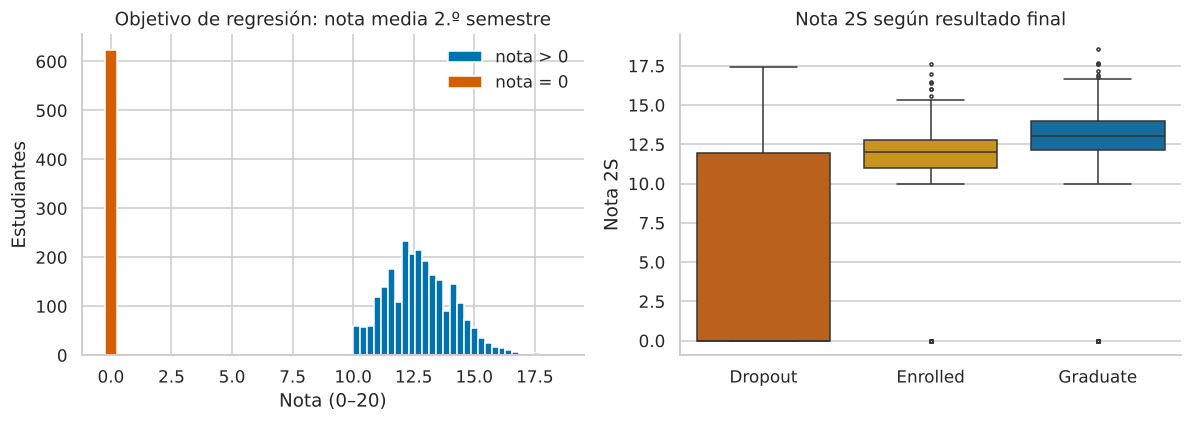

In [5]:
TARGET_REG = "Curricular units 2nd sem (grade)"
yr_tr, yr_va, yr_te = X_tr[TARGET_REG].values, X_va[TARGET_REG].values, X_te[TARGET_REG].values
assert TARGET_REG not in USED
d = pd.Series(yr_tr)
print("Entrenamiento: n=%d | media=%.4f | mediana=%.4f | sd=%.4f | %% de ceros=%.2f%% (n=%d)" % (len(d), d.mean(), d.median(), d.std(), (d==0).mean()*100, int((d==0).sum())))
print("Mínimo positivo:", d[d>0].min(), "| máximo:", d.max())
print("Ceros: nota2S=0 con evaluaciones2S=0 ->", int(((X_tr[TARGET_REG]==0)&(X_tr["Curricular units 2nd sem (evaluations)"]==0)).sum()),
      "| nota2S=0 con evaluaciones2S>0 ->", int(((X_tr[TARGET_REG]==0)&(X_tr["Curricular units 2nd sem (evaluations)"]>0)).sum()),
      "| nota2S=0 y aprobadas2S>0 ->", int(((X_tr[TARGET_REG]==0)&(X_tr["Curricular units 2nd sem (approved)"]>0)).sum()))
print("Correlación de Spearman nota 1S vs nota 2S (entrenamiento): %.4f" % stats.spearmanr(X_tr["Curricular units 1st sem (grade)"], d)[0])
print("Media de nota 2S por Target:"); display(pd.Series(yr_tr).groupby(y_tr.values).agg(["mean","median","count"]))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(d[d>0], bins=30, color="#0072B2", label="nota > 0"); ax[0].bar(0, (d==0).sum(), width=.5, color="#D55E00", label="nota = 0")
ax[0].set_title("Objetivo de regresión: nota media 2.º semestre"); ax[0].set_xlabel("Nota (0–20)"); ax[0].set_ylabel("Estudiantes"); ax[0].legend(frameon=False)
sns.boxplot(x=y_tr.values, y=d.values, order=CLASSES, palette=PAL, ax=ax[1], fliersize=2); ax[1].set_xlabel(""); ax[1].set_ylabel("Nota 2S"); ax[1].set_title("Nota 2S según resultado final")
savefig("r1_objetivo_regresion.png")

In [6]:
# 1.1 Modelos y búsqueda de hiperparámetros (solo entrenamiento; CV 5 pliegues; RMSE)
cv_reg = KFold(5, shuffle=True, random_state=SEED)
def pipe_reg(est): return Pipeline([("pre", build_preprocessor()), ("reg", est)])
n_it = 4 if QUICK else 20
reg_search = {
 "Ridge": GridSearchCV(pipe_reg(Ridge()), {"reg__alpha": np.logspace(-2, 3, 11)}, cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=NJ, return_train_score=True),
 "Lasso": GridSearchCV(pipe_reg(Lasso(max_iter=50000)), {"reg__alpha": np.logspace(-4, 0, 9)}, cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=NJ, return_train_score=True),
 "ElasticNet": GridSearchCV(pipe_reg(ElasticNet(max_iter=50000)), {"reg__alpha": np.logspace(-4, 0, 9), "reg__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 0.95]},
                            cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=NJ, return_train_score=True),
 "RandomForest": RandomizedSearchCV(pipe_reg(RandomForestRegressor(n_estimators=100 if QUICK else 300, random_state=SEED, n_jobs=NJ)),
     {"reg__max_depth": [4, 6, 8, 12, None], "reg__min_samples_leaf": [1, 3, 5, 10, 20], "reg__max_features": ["sqrt", 0.3, 0.5, 1.0], "reg__max_samples": [None, 0.7, 0.9]},
     n_iter=n_it, cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=1, random_state=SEED, return_train_score=True),
 "XGBoost": RandomizedSearchCV(pipe_reg(XGBRegressor(tree_method="hist", random_state=SEED, n_jobs=NJ, verbosity=0)),
     {"reg__n_estimators": [100, 200, 300, 500], "reg__learning_rate": [0.02, 0.05, 0.1], "reg__max_depth": [2, 3, 4, 6], "reg__subsample": [0.7, 0.85, 1.0],
      "reg__colsample_bytree": [0.5, 0.7, 1.0], "reg__min_child_weight": [1, 5, 10], "reg__reg_lambda": [1, 5, 10]},
     n_iter=n_it, cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=1, random_state=SEED, return_train_score=True),
}
reg_models = {"Dummy (media)": Pipeline([("reg", DummyRegressor(strategy="mean"))]).fit(F_tr[["Age at enrollment"]], yr_tr),
              "OLS": pipe_reg(LinearRegression()).fit(F_tr, yr_tr)}
# CV de referencia para Dummy y OLS (mismo esquema de pliegues)
def cv_rmse(model, X, y, cols=None):
    r = []
    for tr, te in cv_reg.split(X):
        m = clone(model).fit(X.iloc[tr] if cols is None else X.iloc[tr][cols], y[tr]); p = m.predict(X.iloc[te] if cols is None else X.iloc[te][cols]); r.append(mean_squared_error(y[te], p) ** .5)
    return np.mean(r), np.std(r)
reg_cv = {"Dummy (media)": cv_rmse(Pipeline([("reg", DummyRegressor())]), F_tr, yr_tr, ["Age at enrollment"]), "OLS": cv_rmse(pipe_reg(LinearRegression()), F_tr, yr_tr)}
reg_best, reg_time, reg_tune = {}, {}, []
for k, s in reg_search.items():
    t0 = time.time(); s.fit(F_tr, yr_tr); reg_time[k] = time.time() - t0
    i = s.best_index_; reg_models[k] = s.best_estimator_; reg_best[k] = {kk.replace("reg__", ""): vv for kk, vv in s.best_params_.items()}
    reg_cv[k] = (-s.cv_results_["mean_test_score"][i], s.cv_results_["std_test_score"][i])
    reg_tune.append({"modelo": k, "n_configuraciones": len(s.cv_results_["params"]), "RMSE_CV": -s.cv_results_["mean_test_score"][i], "sd_CV": s.cv_results_["std_test_score"][i],
                     "RMSE_train_CV": -s.cv_results_["mean_train_score"][i], "tiempo_s": reg_time[k], "mejores_hiperparametros": json.dumps(reg_best[k], default=float)})
    print(f"{k}: RMSE CV={reg_cv[k][0]:.4f} ± {reg_cv[k][1]:.4f} | {reg_best[k]} | {reg_time[k]:.0f}s")
reg_tune = pd.DataFrame(reg_tune).set_index("modelo"); display(reg_tune); reg_tune.to_csv(OUT / "reg_tuning_cv.csv", encoding="utf-8-sig")

Ridge: RMSE CV=2.5930 ± 0.1822 | {'alpha': np.float64(31.622776601683793)} | 2s


Lasso: RMSE CV=2.5821 ± 0.1802 | {'alpha': np.float64(0.01)} | 2s


ElasticNet: RMSE CV=2.5825 ± 0.1803 | {'alpha': np.float64(0.01), 'l1_ratio': 0.95} | 16s


RandomForest: RMSE CV=2.5448 ± 0.1933 | {'min_samples_leaf': 5, 'max_samples': None, 'max_features': 0.5, 'max_depth': 8} | 117s


XGBoost: RMSE CV=2.5200 ± 0.1878 | {'subsample': 0.85, 'reg_lambda': 10, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 0.5} | 21s


,n_configuraciones,RMSE_CV,sd_CV,RMSE_train_CV,tiempo_s,mejores_hiperparametros
modelo,,,,,,
Ridge,11,2.5930,0.1822,2.5091,2.2849,"{""alpha"": 31.622776601683793}"
Lasso,9,2.5821,0.1802,2.5245,2.3171,"{""alpha"": 0.01}"
ElasticNet,54,2.5825,0.1803,2.5236,15.5792,"{""alpha"": 0.01, ""l1_ratio"": 0.95}"
RandomForest,20,2.5448,0.1933,2.0351,117.0667,"{""min_samples_leaf"": 5, ""max_samples"": null, ""..."
XGBoost,20,2.5200,0.1878,2.2233,20.5371,"{""subsample"": 0.85, ""reg_lambda"": 10, ""n_estim..."


In [7]:
# 1.2 Evaluación en VALIDACIÓN (R2, RMSE, MAE; y condicionada a nota 2S > 0)
def m_reg(model, X, y):
    p = model.predict(X); m = y > 0
    return {"R2": r2_score(y, p), "RMSE": mean_squared_error(y, p) ** .5, "MAE": mean_absolute_error(y, p),
            "R2_cond": r2_score(y[m], p[m]), "RMSE_cond": mean_squared_error(y[m], p[m]) ** .5, "MAE_cond": mean_absolute_error(y[m], p[m])}
def Xin(name, X): return X[["Age at enrollment"]] if name.startswith("Dummy") else X
REG_ORDER = ["Dummy (media)", "OLS", "Ridge", "Lasso", "ElasticNet", "RandomForest", "XGBoost"]
reg_val = pd.DataFrame({k: m_reg(reg_models[k], Xin(k, F_va), yr_va) for k in REG_ORDER}).T
reg_val["RMSE_CV_train"] = [reg_cv[k][0] for k in REG_ORDER]; display(reg_val); reg_val.to_csv(OUT / "reg_metricas_validacion.csv", encoding="utf-8-sig")
# Campeón (criterio fijado a priori): menor RMSE en validación entre ElasticNet / RandomForest / XGBoost; si < 1 % del mejor, el más simple
cand = ["ElasticNet", "RandomForest", "XGBoost"]; best_rmse = reg_val.loc[cand, "RMSE"].min()
ok = [m for m in cand if reg_val.loc[m, "RMSE"] <= best_rmse * 1.01]; REG_CHAMP = ok[0]
print("Candidatos dentro de 1 % del mejor RMSE:", ok, "-> CAMPEÓN DE REGRESIÓN:", REG_CHAMP)

,R2,RMSE,MAE,R2_cond,RMSE_cond,MAE_cond,RMSE_CV_train
Dummy (media),-0.0027,5.0723,3.9485,-3.3451,2.9230,2.5740,5.2600
OLS,0.7943,2.2973,1.4199,-0.7323,1.8456,1.2375,2.6120
Ridge,0.7978,2.2776,1.3897,-0.6859,1.8207,1.2100,2.5930
Lasso,0.8011,2.2593,1.3507,-0.6695,1.8118,1.1871,2.5821
ElasticNet,0.8009,2.2604,1.3518,-0.6709,1.8126,1.1875,2.5825
RandomForest,0.8130,2.1907,1.1840,-0.5966,1.7718,1.0456,2.5448
XGBoost,0.8089,2.2141,1.2487,-0.6000,1.7737,1.0759,2.5200


Candidatos dentro de 1 % del mejor RMSE: ['RandomForest'] -> CAMPEÓN DE REGRESIÓN: RandomForest


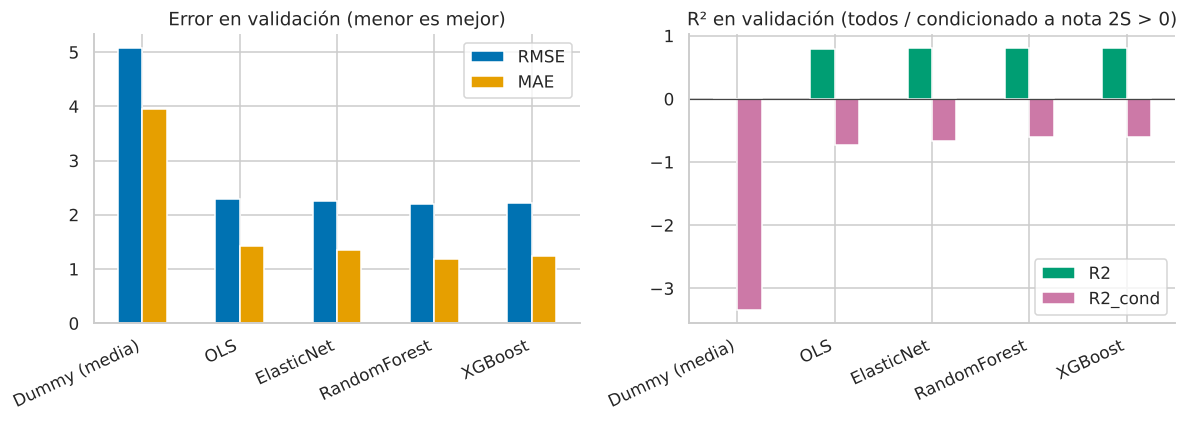

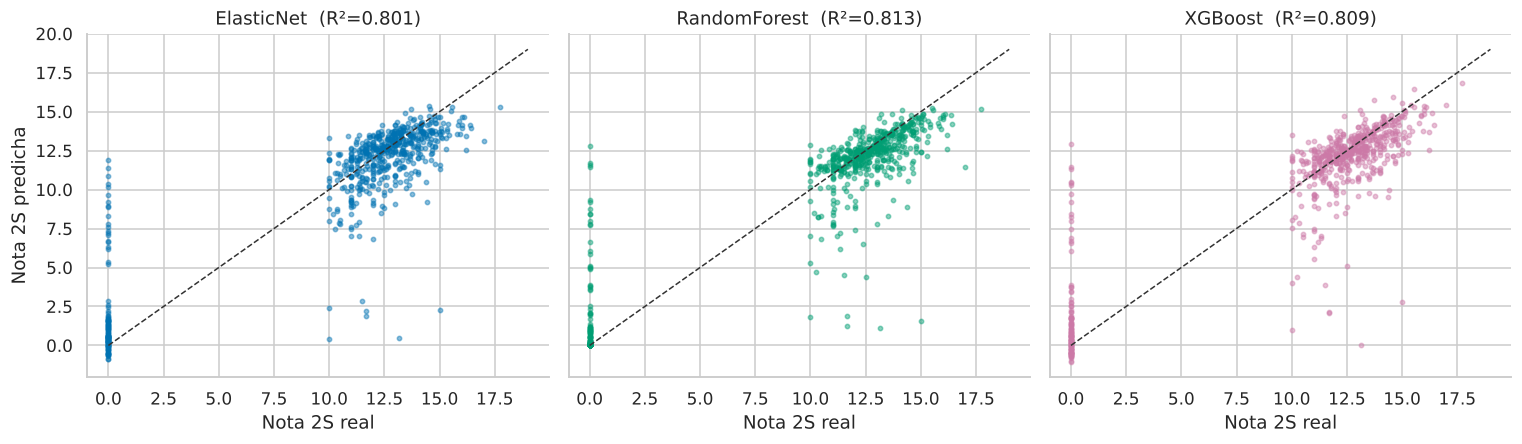

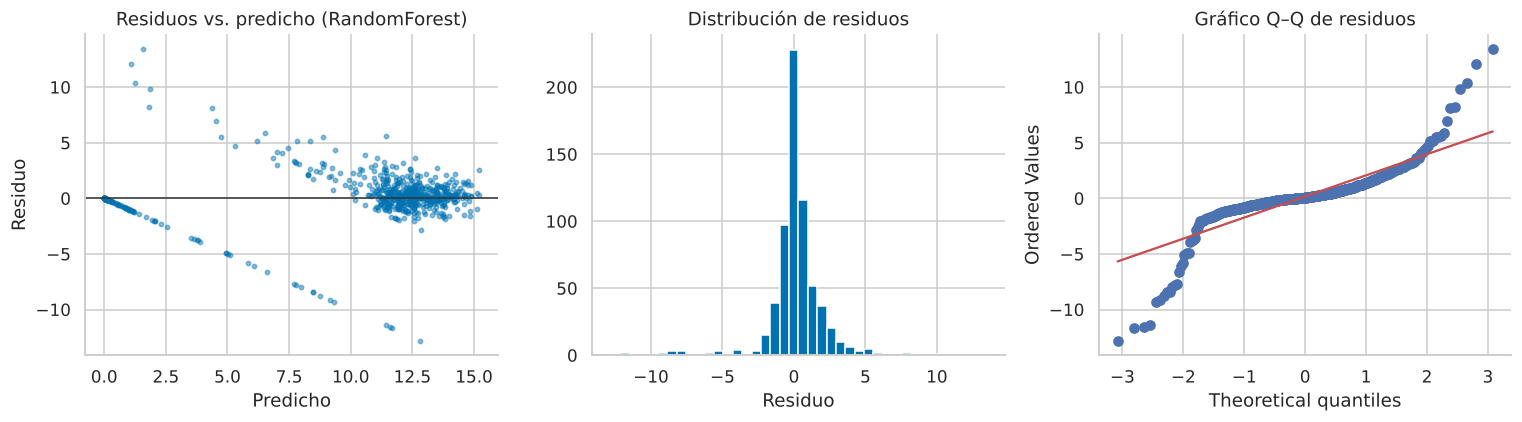

Residuos (val): media=0.1702, sd=2.1841, asimetría=-0.648; Shapiro p=3.22e-30
RMSE por grupo (campeón, val):


,RMSE,sesgo,n
y,,,
Dropout,3.0390,-0.2104,213
Enrolled,2.8243,0.6144,119
Graduate,0.9022,0.2551,332


RMSE para nota real = 0 vs > 0: {'=0': 3.510484453416603, '>0': 1.7718286421699414}


In [8]:
# 1.3 Gráficas de regresión (validación)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
show = ["Dummy (media)", "OLS", "ElasticNet", "RandomForest", "XGBoost"]
reg_val.loc[show, ["RMSE", "MAE"]].plot(kind="bar", ax=ax[0], color=["#0072B2", "#E69F00"], edgecolor="white"); ax[0].set_title("Error en validación (menor es mejor)"); plt.setp(ax[0].get_xticklabels(), rotation=25, ha="right")
reg_val.loc[show, ["R2", "R2_cond"]].plot(kind="bar", ax=ax[1], color=["#009E73", "#CC79A7"], edgecolor="white"); ax[1].axhline(0, color="#444", lw=.8); ax[1].set_title("R² en validación (todos / condicionado a nota 2S > 0)"); plt.setp(ax[1].get_xticklabels(), rotation=25, ha="right")
savefig("r2_comparacion_regresion.png")
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
for a, k, col in zip(axes, ["ElasticNet", "RandomForest", "XGBoost"], MPAL):
    p = reg_models[k].predict(F_va); a.scatter(yr_va, p, s=8, alpha=.45, color=col); a.plot([0, 19], [0, 19], color="#333", lw=1, ls="--")
    a.set_title(f"{k}  (R²={r2_score(yr_va, p):.3f})"); a.set_xlabel("Nota 2S real")
axes[0].set_ylabel("Nota 2S predicha"); savefig("r3_predicho_vs_real.png")
pc = reg_models[REG_CHAMP].predict(F_va); res = yr_va - pc
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].scatter(pc, res, s=8, alpha=.45, color="#0072B2"); ax[0].axhline(0, color="#333", lw=1); ax[0].set_xlabel("Predicho"); ax[0].set_ylabel("Residuo"); ax[0].set_title(f"Residuos vs. predicho ({REG_CHAMP})")
ax[1].hist(res, bins=40, color="#0072B2"); ax[1].set_title("Distribución de residuos"); ax[1].set_xlabel("Residuo")
stats.probplot(res, dist="norm", plot=ax[2]); ax[2].set_title("Gráfico Q–Q de residuos"); savefig("r4_residuos_campeon.png")
print("Residuos (val): media=%.4f, sd=%.4f, asimetría=%.3f; Shapiro p=%.3g" % (res.mean(), res.std(), stats.skew(res), stats.shapiro(res)[1]))
print("RMSE por grupo (campeón, val):"); display(pd.DataFrame({"res": res, "y": y_va.values, "real0": yr_va == 0}).groupby("y")["res"].agg(RMSE=lambda s: np.sqrt((s**2).mean()), sesgo="mean", n="count"))
print("RMSE para nota real = 0 vs > 0:", {"=0": float(np.sqrt((res[yr_va==0]**2).mean())), ">0": float(np.sqrt((res[yr_va>0]**2).mean()))})

# BLOQUE 2 — Clasificación (predicción categórica)

Se comparan **dos algoritmos distintos** —**Random Forest** (ensamble de árboles, no lineal) y **SVM con kernel RBF** (margen máximo en espacio de características)— frente a la **regresión logística** de la Fase 2 como referencia. Siguiendo la decisión de la Fase 2, ambos usan **ponderación de clases balanceada** (`class_weight`), y los hiperparámetros se optimizan con validación cruzada **estratificada de 5 pliegues** maximizando macro-F1, solo sobre entrenamiento. Se reportan exactitud, precisión, recall, F1 (macro y por clase), AUC-ROC (uno-contra-resto, macro) y se diagnostica sobreajuste (puntuación en entrenamiento vs. CV y curvas de aprendizaje).

In [9]:
cv_cls = StratifiedKFold(5, shuffle=True, random_state=SEED)
def pipe_cls(est): return Pipeline([("pre", build_preprocessor()), ("clf", est)])
cls_search = {
 "RandomForest": RandomizedSearchCV(pipe_cls(RandomForestClassifier(n_estimators=100 if QUICK else 300, class_weight="balanced_subsample", random_state=SEED, n_jobs=NJ)),
     {"clf__max_depth": [4, 6, 8, 12, 16, None], "clf__min_samples_leaf": [1, 2, 5, 10, 20], "clf__max_features": ["sqrt", "log2", 0.2, 0.4],
      "clf__min_samples_split": [2, 5, 10], "clf__max_samples": [None, 0.7, 0.9]},
     n_iter=4 if QUICK else 20, cv=cv_cls, scoring="f1_macro", n_jobs=1, random_state=SEED, return_train_score=True),
 "SVM (RBF)": GridSearchCV(pipe_cls(SVC(kernel="rbf", class_weight="balanced", random_state=SEED)),
     {"clf__C": [0.3, 1, 3] if QUICK else [0.3, 1, 3, 10, 30], "clf__gamma": ["scale", 0.003] if QUICK else ["scale", 0.001, 0.003, 0.01]},
     cv=cv_cls, scoring="f1_macro", n_jobs=NJ, return_train_score=True),
}
cls_models, cls_best, cls_tune = {"Regresión logística (Fase 2)": base_lr}, {}, []
for k, s in cls_search.items():
    t0 = time.time(); s.fit(F_tr, y_tr); tt = time.time() - t0; i = s.best_index_
    cls_models[k] = s.best_estimator_; cls_best[k] = {kk.replace("clf__", ""): vv for kk, vv in s.best_params_.items()}
    cls_tune.append({"modelo": k, "n_configuraciones": len(s.cv_results_["params"]), "macroF1_CV": s.cv_results_["mean_test_score"][i], "sd_CV": s.cv_results_["std_test_score"][i],
                     "macroF1_train_CV": s.cv_results_["mean_train_score"][i], "brecha_train-CV": s.cv_results_["mean_train_score"][i] - s.cv_results_["mean_test_score"][i],
                     "tiempo_s": tt, "mejores_hiperparametros": json.dumps(cls_best[k], default=str)})
    print(f"{k}: macro-F1 CV={s.cv_results_['mean_test_score'][i]:.4f} ± {s.cv_results_['std_test_score'][i]:.4f} | {cls_best[k]} | {tt:.0f}s")
# CV de la referencia (LR Fase 2) con el mismo esquema
cvlr = cross_val_predict(clone(base_lr), F_tr, y_tr, cv=cv_cls); lr_f1_cv = np.mean([f1_score(y_tr.iloc[te], cvlr[te], average="macro") for _, te in cv_cls.split(F_tr, y_tr)])
cls_tune = pd.DataFrame(cls_tune).set_index("modelo"); display(cls_tune); print("LR (Fase 2) macro-F1 CV: %.4f" % lr_f1_cv)
cls_tune.to_csv(OUT / "cls_tuning_cv.csv", encoding="utf-8-sig")
# Configuraciones: top-10 por búsqueda (para la figura de sensibilidad a hiperparámetros)
cvres = {k: pd.DataFrame(s.cv_results_).sort_values("rank_test_score").head(10)[["mean_test_score", "mean_train_score", "params"]] for k, s in cls_search.items()}
for k in cvres: cvres[k]["params"] = cvres[k]["params"].astype(str)
pd.concat(cvres, names=["modelo"]).to_csv(OUT / "cls_top10_configuraciones.csv", encoding="utf-8-sig")

RandomForest: macro-F1 CV=0.6816 ± 0.0197 | {'min_samples_split': 2, 'min_samples_leaf': 2, 'max_samples': None, 'max_features': 'log2', 'max_depth': 12} | 113s


SVM (RBF): macro-F1 CV=0.6832 ± 0.0188 | {'C': 1, 'gamma': 'scale'} | 42s


,n_configuraciones,macroF1_CV,sd_CV,macroF1_train_CV,brecha_train-CV,tiempo_s,mejores_hiperparametros
modelo,,,,,,,
RandomForest,20,0.6816,0.0197,0.8499,0.1683,112.6164,"{""min_samples_split"": 2, ""min_samples_leaf"": 2..."
SVM (RBF),20,0.6832,0.0188,0.7971,0.1139,42.4938,"{""C"": 1, ""gamma"": ""scale""}"


LR (Fase 2) macro-F1 CV: 0.6726


In [10]:
# Modelos finales con probabilidades (SVM con calibración de Platt interna; predict() no cambia)
svm_prob = clone(cls_models["SVM (RBF)"]).set_params(clf__probability=True).fit(F_tr, y_tr)
assert (svm_prob.predict(F_va) == cls_models["SVM (RBF)"].predict(F_va)).mean() > 0.99
cls_models["SVM (RBF)"] = svm_prob
CLS_ORDER = ["Regresión logística (Fase 2)", "RandomForest", "SVM (RBF)"]

def m_cls(model, X, y):
    pred = model.predict(X); proba = model.predict_proba(X); rep = classification_report(y, pred, labels=CLASSES, output_dict=True, zero_division=0)
    Y = label_binarize(y, classes=CLASSES)
    o = {"accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred), "precision_macro": rep["macro avg"]["precision"],
         "recall_macro": rep["macro avg"]["recall"], "F1_macro": rep["macro avg"]["f1-score"], "F1_weighted": rep["weighted avg"]["f1-score"],
         "AUC_ROC_macro": roc_auc_score(y, proba, multi_class="ovr", average="macro", labels=CLASSES), "log_loss": log_loss(y, proba, labels=CLASSES)}
    for j, c in enumerate(CLASSES):
        o[f"P_{c}"], o[f"R_{c}"], o[f"F1_{c}"] = rep[c]["precision"], rep[c]["recall"], rep[c]["f1-score"]; o[f"AUC_{c}"] = roc_auc_score(Y[:, j], proba[:, j])
    return o
cls_val = pd.DataFrame({k: m_cls(cls_models[k], F_va, y_va) for k in CLS_ORDER}).T; display(cls_val); cls_val.to_csv(OUT / "cls_metricas_validacion.csv", encoding="utf-8-sig")
# Campeón (criterio a priori): mayor macro-F1 en validación entre RF y SVM; si la diferencia < 0.01, mayor AUC-ROC macro
cands = ["RandomForest", "SVM (RBF)"]; bf = cls_val.loc[cands, "F1_macro"].max(); ok = [m for m in cands if cls_val.loc[m, "F1_macro"] >= bf - 0.01]
CLS_CHAMP = max(ok, key=lambda m: cls_val.loc[m, "AUC_ROC_macro"]) if len(ok) > 1 else ok[0]
print("Candidatos (dif. < 0.01 en macro-F1):", ok, "-> CAMPEÓN DE CLASIFICACIÓN:", CLS_CHAMP)
# Pruebas de McNemar entre pares (validación)
pv = {k: cls_models[k].predict(F_va) for k in CLS_ORDER}; rows = []
for a, b in [(CLS_ORDER[1], CLS_ORDER[2]), (CLS_ORDER[0], CLS_ORDER[1]), (CLS_ORDER[0], CLS_ORDER[2])]:
    ca, cb = pv[a] == y_va.values, pv[b] == y_va.values
    t = [[int((ca & cb).sum()), int((ca & ~cb).sum())], [int((~ca & cb).sum()), int((~ca & ~cb).sum())]]; r = mcnemar(t, exact=False, correction=True)
    rows.append({"A": a, "B": b, "A_acierta_B_falla": t[0][1], "A_falla_B_acierta": t[1][0], "chi2": r.statistic, "valor_p": r.pvalue})
mc = pd.DataFrame(rows); display(mc); mc.to_csv(OUT / "cls_mcnemar_validacion.csv", index=False, encoding="utf-8-sig")

,accuracy,balanced_acc,precision_macro,recall_macro,F1_macro,F1_weighted,AUC_ROC_macro,log_loss,P_Dropout,R_Dropout,F1_Dropout,AUC_Dropout,P_Enrolled,R_Enrolled,F1_Enrolled,AUC_Enrolled,P_Graduate,R_Graduate,F1_Graduate,AUC_Graduate
Regresión logística (Fase 2),0.6988,0.6779,0.6733,0.6779,0.6648,0.7123,0.8597,0.6996,0.7921,0.6620,0.7212,0.8789,0.3978,0.6218,0.4852,0.7992,0.8300,0.7500,0.7880,0.9012
RandomForest,0.7184,0.6686,0.6670,0.6686,0.6660,0.7235,0.8505,0.7133,0.7526,0.6854,0.7174,0.8746,0.4196,0.5042,0.4580,0.7758,0.8287,0.8163,0.8225,0.9010
SVM (RBF),0.6973,0.6682,0.6708,0.6682,0.6581,0.7111,0.8545,0.6477,0.7988,0.6338,0.7068,0.8825,0.3817,0.5966,0.4656,0.7755,0.8317,0.7741,0.8019,0.9054


Candidatos (dif. < 0.01 en macro-F1): ['RandomForest', 'SVM (RBF)'] -> CAMPEÓN DE CLASIFICACIÓN: SVM (RBF)


,A,B,A_acierta_B_falla,A_falla_B_acierta,chi2,valor_p
0,RandomForest,SVM (RBF),45,31,2.2237,0.1359
1,Regresión logística (Fase 2),RandomForest,41,54,1.5158,0.2183
2,Regresión logística (Fase 2),SVM (RBF),44,43,0.0000,1.0000


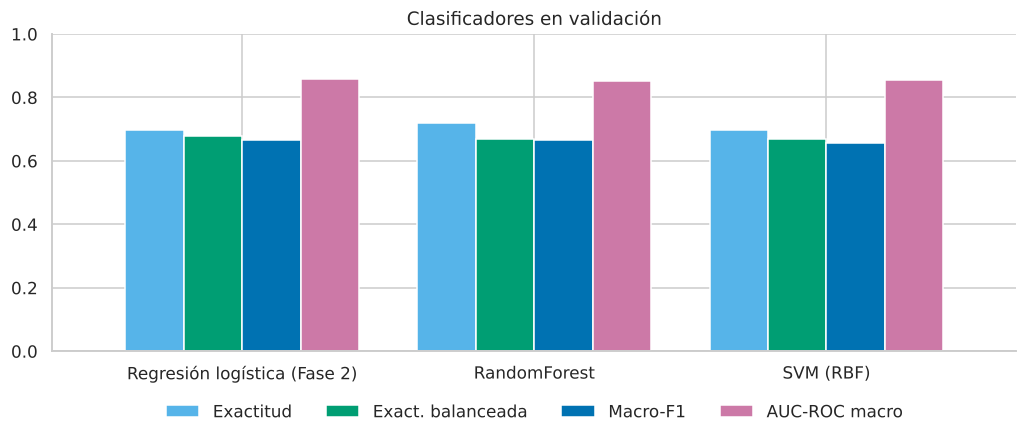

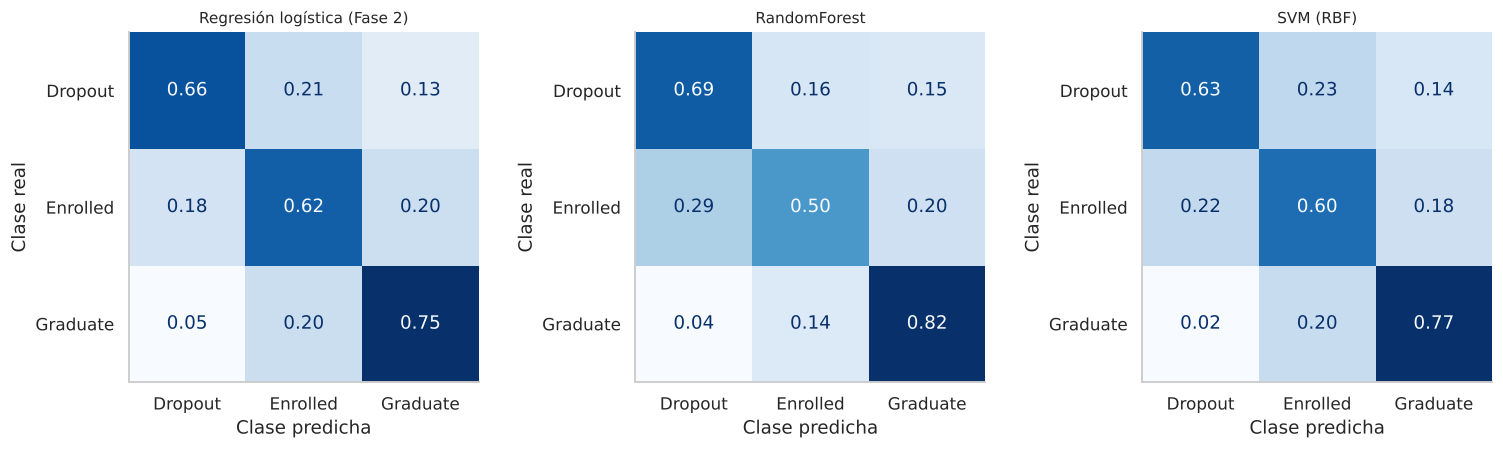

Regresión logística (Fase 2)


,pred_Dropout,pred_Enrolled,pred_Graduate
real_Dropout,141,45,27
real_Enrolled,21,74,24
real_Graduate,16,67,249


RandomForest


,pred_Dropout,pred_Enrolled,pred_Graduate
real_Dropout,146,35,32
real_Enrolled,35,60,24
real_Graduate,13,48,271


SVM (RBF)


,pred_Dropout,pred_Enrolled,pred_Graduate
real_Dropout,135,48,30
real_Enrolled,26,71,22
real_Graduate,8,67,257


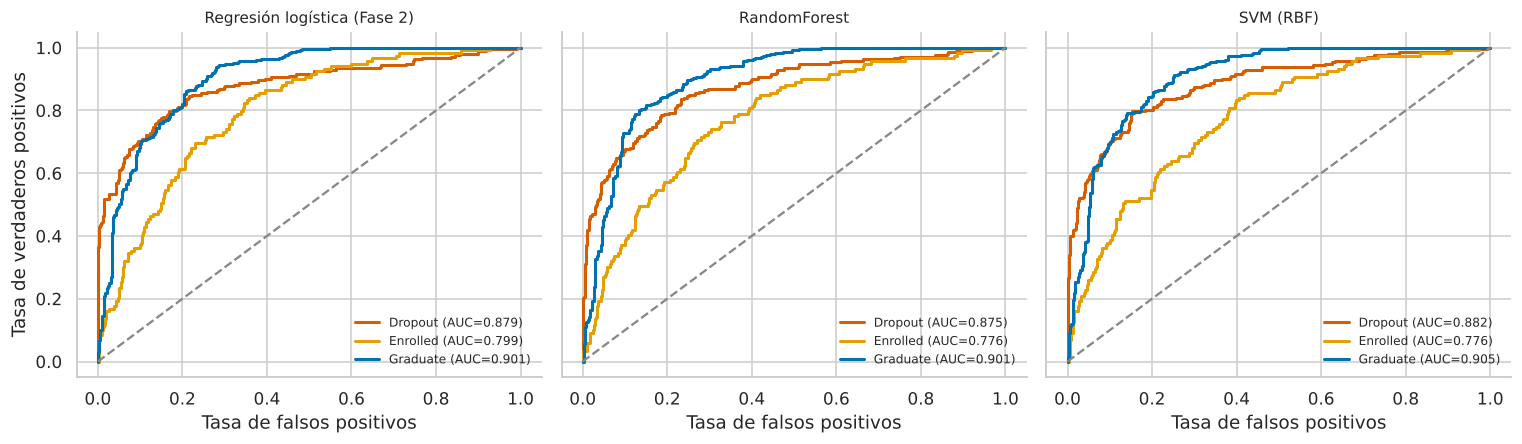

In [11]:
# Gráficas de clasificación (validación)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
cls_val.loc[CLS_ORDER, ["accuracy", "balanced_acc", "F1_macro", "AUC_ROC_macro"]].rename(columns={"accuracy": "Exactitud", "balanced_acc": "Exact. balanceada", "F1_macro": "Macro-F1", "AUC_ROC_macro": "AUC-ROC macro"}).plot(kind="bar", ax=ax, color=["#56B4E9", "#009E73", "#0072B2", "#CC79A7"], edgecolor="white", width=.8)
ax.set_ylim(0, 1); ax.set_title("Clasificadores en validación"); plt.setp(ax.get_xticklabels(), rotation=0); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.12), ncol=4)
savefig("c1_comparacion_clasificadores.png")
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for a, k in zip(axes, CLS_ORDER):
    ConfusionMatrixDisplay.from_predictions(y_va, cls_models[k].predict(F_va), labels=CLASSES, normalize="true", values_format=".2f", ax=a, cmap="Blues", colorbar=False)
    a.set_title(k, fontsize=10); a.set_xlabel("Clase predicha"); a.set_ylabel("Clase real"); a.grid(False)
savefig("c2_matrices_confusion.png")
for k in CLS_ORDER: print(k); display(pd.DataFrame(confusion_matrix(y_va, cls_models[k].predict(F_va), labels=CLASSES), index=[f"real_{c}" for c in CLASSES], columns=[f"pred_{c}" for c in CLASSES]))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True); Yv = label_binarize(y_va, classes=CLASSES)
for a, k in zip(axes, CLS_ORDER):
    P = cls_models[k].predict_proba(F_va)
    for j, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(Yv[:, j], P[:, j]); a.plot(fpr, tpr, color=PAL[c], lw=2, label=f"{c} (AUC={auc(fpr, tpr):.3f})")
    a.plot([0, 1], [0, 1], "--", color="#888"); a.set_title(k, fontsize=10); a.set_xlabel("Tasa de falsos positivos"); a.legend(frameon=False, loc="lower right", fontsize=8)
axes[0].set_ylabel("Tasa de verdaderos positivos"); savefig("c3_curvas_roc.png")

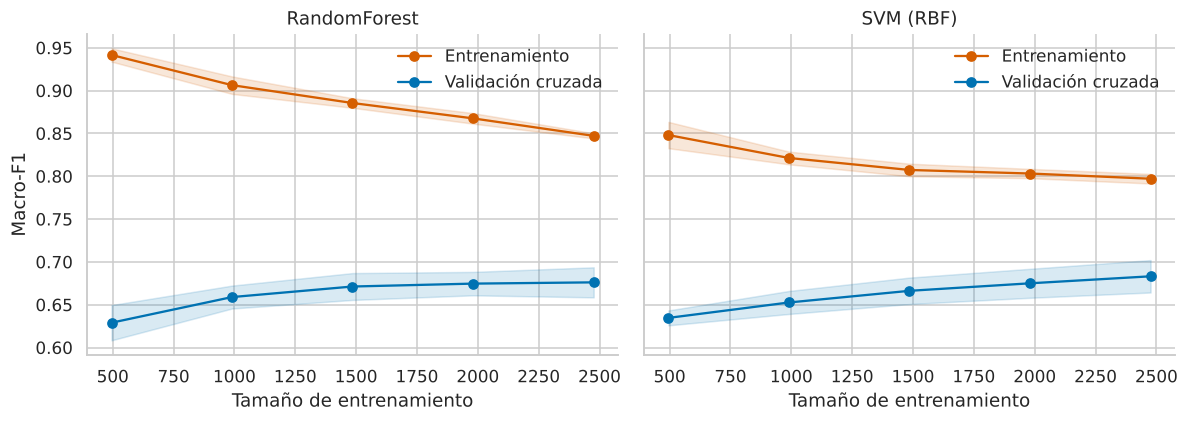

,modelo,n_train,macroF1_train,macroF1_cv,brecha
0,RandomForest,495,0.9416,0.6289,0.3126
1,RandomForest,990,0.9063,0.6589,0.2474
2,RandomForest,1485,0.8855,0.6712,0.2143
3,RandomForest,1980,0.8675,0.6746,0.1930
4,RandomForest,2476,0.8471,0.6761,0.1710
5,SVM (RBF),495,0.8480,0.6346,0.2135
6,SVM (RBF),990,0.8213,0.6526,0.1687
7,SVM (RBF),1485,0.8073,0.6662,0.1411
8,SVM (RBF),1980,0.8031,0.6749,0.1282
9,SVM (RBF),2476,0.7971,0.6831,0.1139


In [12]:
# Diagnóstico de sobreajuste: curvas de aprendizaje (macro-F1) de los dos algoritmos ajustados
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True); lc_rows = []
for a, k in zip(axes, ["RandomForest", "SVM (RBF)"]):
    est = clone(cls_search[k].best_estimator_)
    sz, trs, tes = learning_curve(est, F_tr, y_tr, cv=cv_cls, scoring="f1_macro", train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], n_jobs=NJ, random_state=SEED, shuffle=True)
    a.plot(sz, trs.mean(1), "o-", color="#D55E00", label="Entrenamiento"); a.fill_between(sz, trs.mean(1) - trs.std(1), trs.mean(1) + trs.std(1), color="#D55E00", alpha=.15)
    a.plot(sz, tes.mean(1), "o-", color="#0072B2", label="Validación cruzada"); a.fill_between(sz, tes.mean(1) - tes.std(1), tes.mean(1) + tes.std(1), color="#0072B2", alpha=.15)
    a.set_title(k); a.set_xlabel("Tamaño de entrenamiento"); a.legend(frameon=False)
    for s_, t_, e_ in zip(sz, trs.mean(1), tes.mean(1)): lc_rows.append({"modelo": k, "n_train": int(s_), "macroF1_train": t_, "macroF1_cv": e_, "brecha": t_ - e_})
axes[0].set_ylabel("Macro-F1"); savefig("c4_curvas_aprendizaje.png")
lc = pd.DataFrame(lc_rows); display(lc); lc.to_csv(OUT / "cls_curvas_aprendizaje.csv", index=False, encoding="utf-8-sig")

## Interpretabilidad (clasificación y regresión)

Se combinan cuatro enfoques complementarios: **(i) importancia por permutación** sobre las variables originales (se permuta cada columna *antes* del pipeline, de modo que las variables categóricas se evalúan completas y no por cada columna *one-hot*), **(ii) SHAP** para el modelo de árboles (valores agregados por variable original), **(iii) dependencia parcial** de las variables más relevantes y **(iv) coeficientes** del modelo lineal regularizado. Las importancias se calculan en **validación** (nunca en prueba). Advertencia: variables muy correlacionadas (p. ej., aprobadas, tasa de aprobación) comparten importancia, por lo que no deben leerse como efectos independientes ni causales.

Clasificación (SVM (RBF)): caída de macro-F1 al permutar


,importancia,sd
riesgo_financiero,0.0505,0.0098
tasa_aprobacion_1s,0.0504,0.0067
tasa_exito_eval_1s,0.0501,0.0135
Curricular units 1st sem (approved),0.0486,0.0105
Curricular units 1st sem (grade),0.0270,0.0092
Age at enrollment,0.0135,0.0051
GDP,0.0122,0.0063
Application mode,0.0103,0.0046
Course,0.0099,0.0080
Curricular units 1st sem (evaluations),0.0092,0.0065


Regresión (RandomForest): aumento de RMSE al permutar


,importancia,sd
tasa_aprobacion_1s,1.6188,0.0687
tasa_exito_eval_1s,0.3819,0.0265
Curricular units 1st sem (approved),0.3414,0.0300
Curricular units 1st sem (grade),0.2682,0.0206
Curricular units 1st sem (evaluations),0.0873,0.0162
Course,0.0195,0.0066
GDP,0.0108,0.0035
Unemployment rate,0.0088,0.0092
Father's qualification,0.0087,0.0031
Inflation rate,0.0078,0.0076


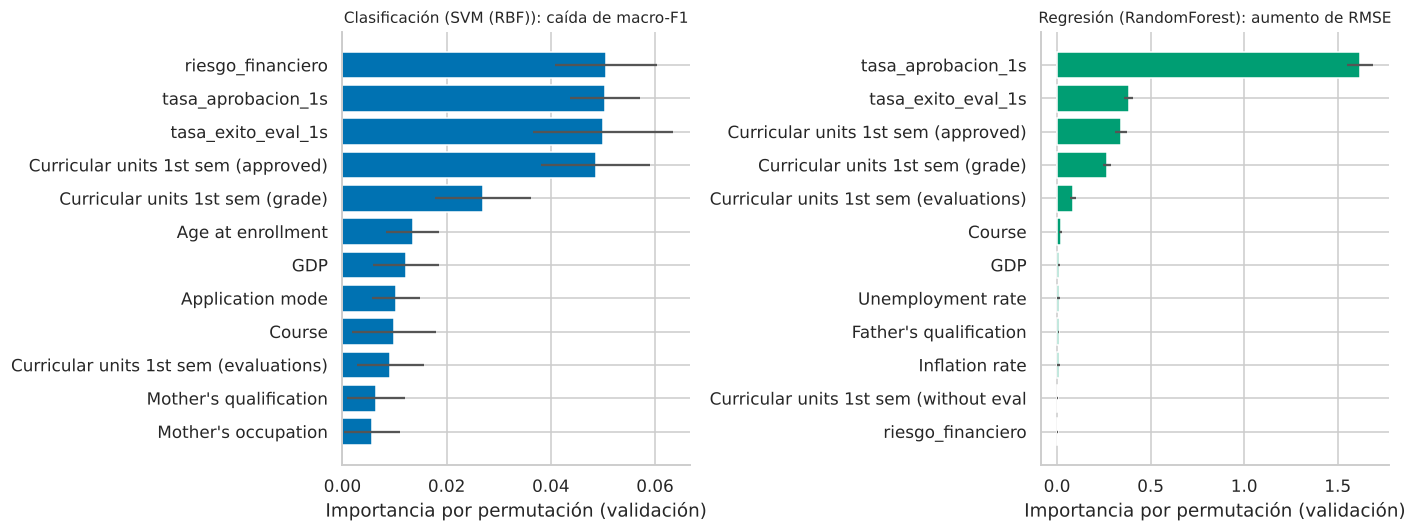

In [13]:
def perm_imp(model, X, y, scoring, n_rep):
    r = permutation_importance(model, X[USED], y, scoring=scoring, n_repeats=n_rep, random_state=SEED, n_jobs=NJ)
    return pd.DataFrame({"importancia": r.importances_mean, "sd": r.importances_std}, index=USED).sort_values("importancia", ascending=False)
nrep = 3 if QUICK else 15
pi_cls = perm_imp(cls_models[CLS_CHAMP], F_va, y_va, "f1_macro", nrep); pi_reg = perm_imp(reg_models[REG_CHAMP], F_va, yr_va, "neg_root_mean_squared_error", nrep)
pi_cls.to_csv(OUT / "importancia_permutacion_clasificacion.csv", encoding="utf-8-sig"); pi_reg.to_csv(OUT / "importancia_permutacion_regresion.csv", encoding="utf-8-sig")
print("Clasificación (%s): caída de macro-F1 al permutar" % CLS_CHAMP); display(pi_cls.head(12))
print("Regresión (%s): aumento de RMSE al permutar" % REG_CHAMP); display(pi_reg.head(12))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, pi, tt, col in [(ax[0], pi_cls, f"Clasificación ({CLS_CHAMP}): caída de macro-F1", "#0072B2"), (ax[1], pi_reg, f"Regresión ({REG_CHAMP}): aumento de RMSE", "#009E73")]:
    t = pi.head(12)[::-1]; a.barh([i[:38] for i in t.index], t["importancia"], xerr=t["sd"], color=col, ecolor="#555"); a.set_title(tt, fontsize=10); a.set_xlabel("Importancia por permutación (validación)")
savefig("i1_importancia_permutacion.png")

,Dropout,Enrolled,Graduate,total
tasa_aprobacion_1s,0.0556,0.0243,0.0658,0.1457
tasa_exito_eval_1s,0.0410,0.0298,0.0563,0.1272
Curricular units 1st sem (approved),0.0375,0.0174,0.0410,0.0958
Curricular units 1st sem (grade),0.0288,0.0191,0.0306,0.0784
Tuition fees up to date,0.0296,0.0139,0.0158,0.0593
riesgo_financiero,0.0290,0.0106,0.0189,0.0585
Scholarship holder,0.0148,0.0134,0.0279,0.0561
Age at enrollment,0.0191,0.0094,0.0124,0.0409
Curricular units 1st sem (evaluations),0.0082,0.0175,0.0133,0.0389
Course,0.0107,0.0112,0.0156,0.0375


,mean|SHAP| (puntos de nota)
tasa_aprobacion_1s,1.7848
Curricular units 1st sem (approved),0.7477
tasa_exito_eval_1s,0.7046
Curricular units 1st sem (grade),0.5395
Curricular units 1st sem (evaluations),0.1638
Admission grade,0.0571
Age at enrollment,0.0424
Application mode,0.0424
sin_evaluaciones_1s,0.0421
Course,0.0404


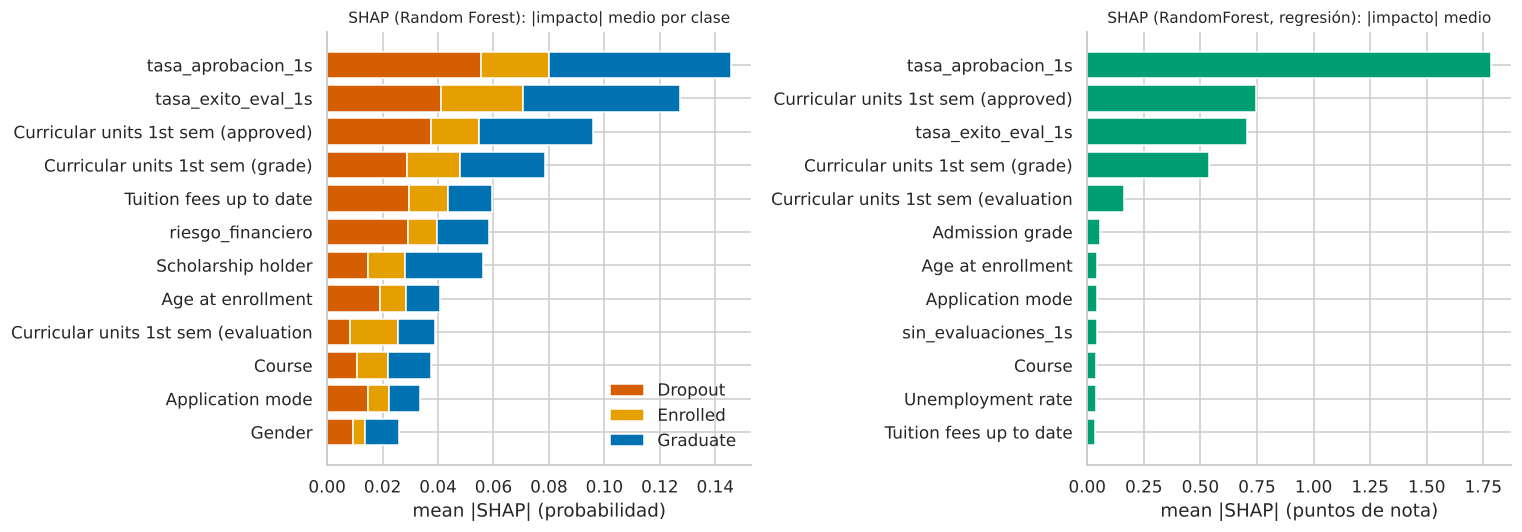

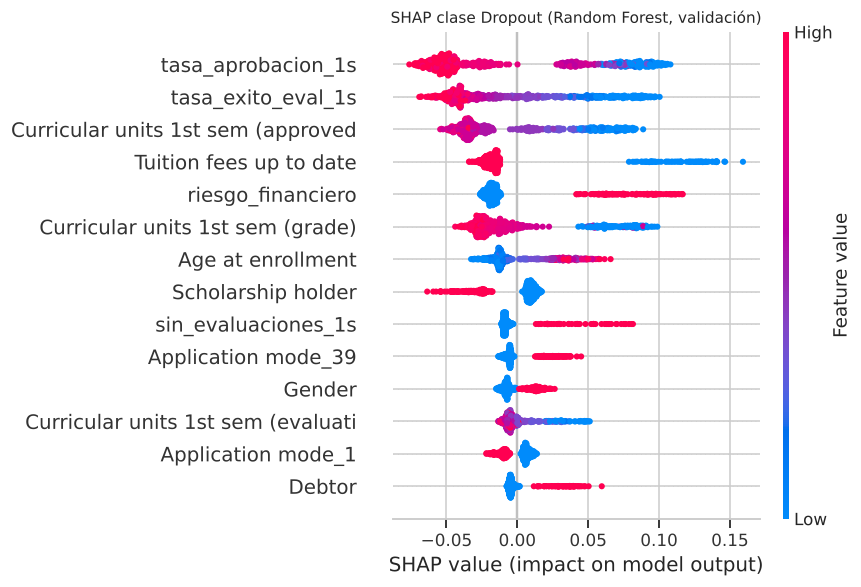

In [14]:
# SHAP: Random Forest (clasificación) y mejor modelo de árboles en regresión; valores agregados por variable original
def var_of(n): return re.sub(r"_[^_]*$", "", n.split("__", 1)[1]) if n.startswith("nom__") else n.split("__", 1)[1]
def shap_agg(pipe, step, X, n_max):
    Xs = X[USED].sample(min(n_max, len(X)), random_state=SEED); pre = pipe.named_steps["pre"]; Z = pre.transform(Xs); names = list(pre.get_feature_names_out())
    ex = shap.TreeExplainer(pipe.named_steps[step]); sv = ex.shap_values(Z, check_additivity=False)
    sv = np.array(sv) if isinstance(sv, list) else sv; return sv, Z, names
nshap = 150 if QUICK else 664
sv_c, Z_c, nm_c = shap_agg(cls_models["RandomForest"], "clf", F_va, nshap)       # (n, f, clases) o lista
if sv_c.ndim == 3 and sv_c.shape[0] == len(CLASSES): sv_c = np.transpose(sv_c, (1, 2, 0))
vars_c = np.array([var_of(n) for n in nm_c]); uv = list(dict.fromkeys(vars_c))
agg = {c: pd.Series({v: np.abs(sv_c[:, vars_c == v, j].sum(1)).mean() for v in uv}) for j, c in enumerate(CLASSES)}
shap_cls = pd.DataFrame(agg); shap_cls["total"] = shap_cls.sum(1); shap_cls = shap_cls.sort_values("total", ascending=False); display(shap_cls.head(12)); shap_cls.to_csv(OUT / "shap_clasificacion_RF.csv", encoding="utf-8-sig")
# Regresión: mejor modelo de árboles (RF o XGB) según RMSE de validación
TREE_REG = "RandomForest" if reg_val.loc["RandomForest", "RMSE"] <= reg_val.loc["XGBoost", "RMSE"] else "XGBoost"
sv_r, Z_r, nm_r = shap_agg(reg_models[TREE_REG], "reg", F_va, nshap); vars_r = np.array([var_of(n) for n in nm_r]); uvr = list(dict.fromkeys(vars_r))
shap_reg = pd.Series({v: np.abs(sv_r[:, vars_r == v].sum(1)).mean() for v in uvr}).sort_values(ascending=False); display(shap_reg.head(12).to_frame("mean|SHAP| (puntos de nota)")); shap_reg.to_csv(OUT / "shap_regresion.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
t = shap_cls.head(12)[::-1]; left = np.zeros(len(t))
for c in CLASSES: ax[0].barh([i[:36] for i in t.index], t[c], left=left, color=PAL[c], label=c, edgecolor="white"); left += t[c].values
ax[0].set_title("SHAP (Random Forest): |impacto| medio por clase", fontsize=10); ax[0].set_xlabel("mean |SHAP| (probabilidad)"); ax[0].legend(frameon=False)
t = shap_reg.head(12)[::-1]; ax[1].barh([i[:36] for i in t.index], t.values, color="#009E73"); ax[1].set_title(f"SHAP ({TREE_REG}, regresión): |impacto| medio", fontsize=10); ax[1].set_xlabel("mean |SHAP| (puntos de nota)")
savefig("i2_shap_por_variable.png")
# Beeswarm clase Dropout (columnas transformadas, nombres legibles)
lab = [n.split("__", 1)[1][:34] for n in nm_c]
plt.figure(figsize=(8, 5.5)); shap.summary_plot(sv_c[:, :, 0], Z_c, feature_names=lab, max_display=14, show=False, plot_size=None); plt.title("SHAP clase Dropout (Random Forest, validación)", fontsize=10); savefig("i3_shap_beeswarm_dropout.png")

PDP clasificación: ['riesgo_financiero', 'tasa_aprobacion_1s', 'tasa_exito_eval_1s'] | regresión: ['tasa_aprobacion_1s', 'tasa_exito_eval_1s', 'Curricular units 1st sem (approved)']


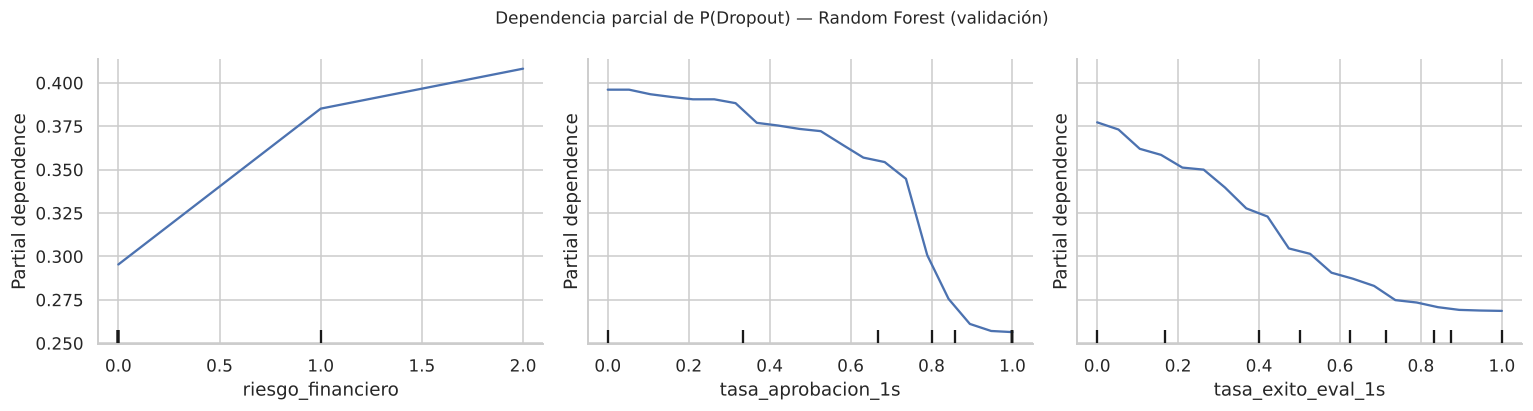

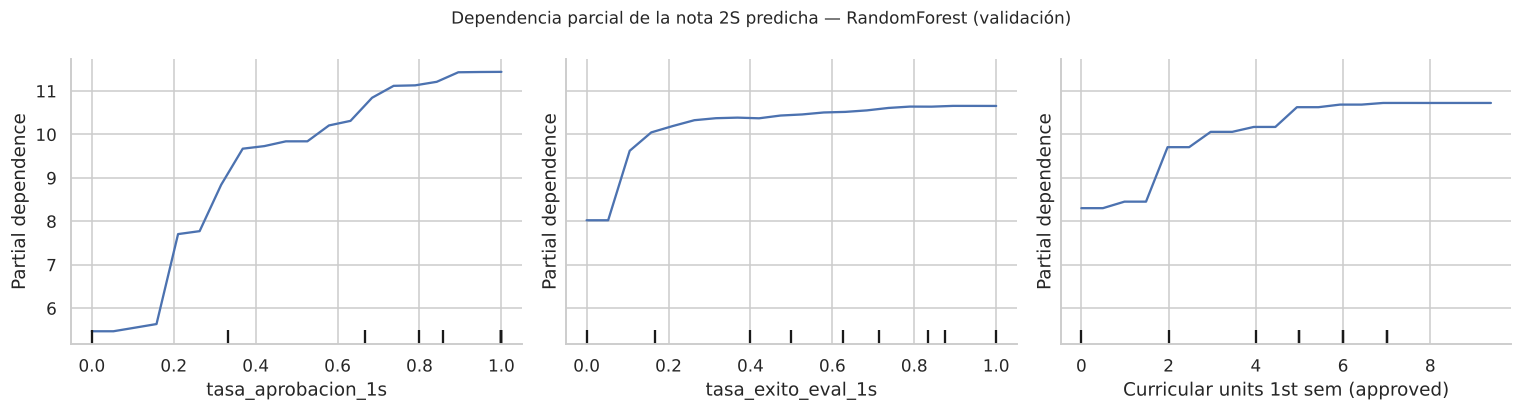

ElasticNet: 48 coeficientes distintos de cero de 107


,coeficiente
num_lin__tasa_aprobacion_1s,2.2628
num_lin__Curricular units 1st sem (grade),2.0322
nom__Mother's occupation_0,-1.1573
nom__Course_9119,1.1306
bin__sin_evaluaciones_1s,-0.7029
nom__Application mode_43,0.5468
nom__Course_9500,0.5101
nom__Father's occupation_90,-0.5044
nom__Previous qualification_39,0.4655
nom__Course_9130,0.4160


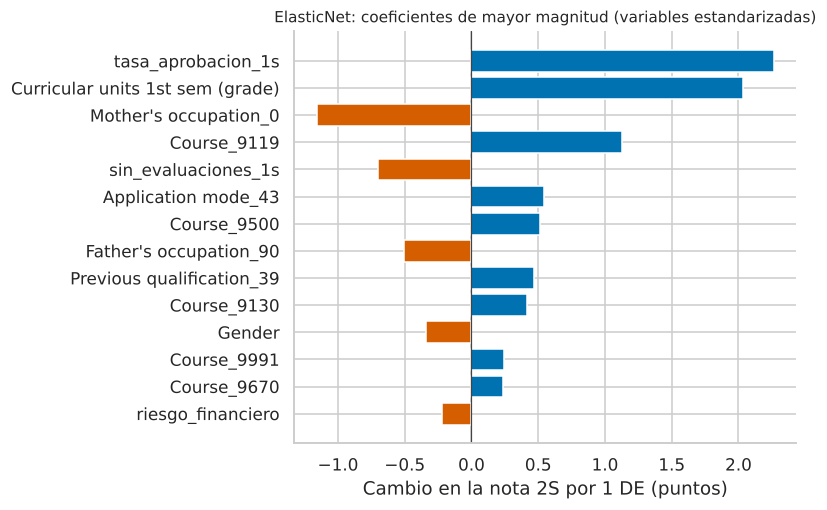

In [15]:
# Dependencia parcial (PDP) de las variables más relevantes
Xpdp = F_va[USED].copy(); Xpdp[NUM_BASE] = Xpdp[NUM_BASE].astype(float)   # PDP exige columnas numéricas en coma flotante
top_c = [v for v in pi_cls.index if v in NUM_BASE][:3]; top_r = [v for v in pi_reg.index if v in NUM_BASE][:3]; print("PDP clasificación:", top_c, "| regresión:", top_r)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
PartialDependenceDisplay.from_estimator(cls_models["RandomForest"], Xpdp, top_c, target="Dropout", kind="average", grid_resolution=20, ax=axes, n_jobs=1)
fig.suptitle("Dependencia parcial de P(Dropout) — Random Forest (validación)", fontsize=11); savefig("i4_pdp_dropout.png")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
PartialDependenceDisplay.from_estimator(reg_models[TREE_REG], Xpdp, top_r, kind="average", grid_resolution=20, ax=axes, n_jobs=1)
fig.suptitle(f"Dependencia parcial de la nota 2S predicha — {TREE_REG} (validación)", fontsize=11); savefig("i5_pdp_regresion.png")
# Coeficientes de ElasticNet (estandarizados)
en = reg_models["ElasticNet"]; coef = pd.Series(en.named_steps["reg"].coef_, index=en.named_steps["pre"].get_feature_names_out()).sort_values(key=np.abs, ascending=False)
print("ElasticNet: %d coeficientes distintos de cero de %d" % ((coef != 0).sum(), len(coef))); display(coef.head(12).to_frame("coeficiente")); coef.to_csv(OUT / "elasticnet_coeficientes.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(7.5, 4.8)); t = coef.head(14)[::-1]; ax.barh([i.split("__", 1)[1][:36] for i in t.index], t.values, color=["#D55E00" if v < 0 else "#0072B2" for v in t.values])
ax.axvline(0, color="#444", lw=.8); ax.set_title("ElasticNet: coeficientes de mayor magnitud (variables estandarizadas)", fontsize=10); ax.set_xlabel("Cambio en la nota 2S por 1 DE (puntos)"); savefig("i6_coeficientes_elasticnet.png")

# BLOQUE 3 — Aprendizaje no supervisado (clustering / segmentación)

**Objetivo:** descubrir perfiles de estudiantes **sin usar `Target`** ni las variables del 2.º semestre en el ajuste, y evaluar después su valor práctico para la permanencia (perfilado *post hoc*).

**Variables de segmentación (16):** edad, nota de admisión, nota previa, orden de aplicación; unidades matriculadas, aprobadas, nota media, sin evaluaciones y convalidadas del 1.er semestre; tasa de aprobación 1S; deudor, matrícula al día, beca, desplazado, género y horario diurno/nocturno. Se excluyen las variables macroeconómicas (identifican la cohorte, no al estudiante) y las nominales de alta cardinalidad (curso, ocupaciones, cualificaciones), que se usan solo para perfilar. Las numéricas se winsorizan/transforman y estandarizan con parámetros de **entrenamiento**; las binarias se mantienen en 0/1.

**Algoritmos:** K-Means (K por codo y silueta), **Agglomerative (Ward)** como segundo algoritmo y **DBSCAN** como contraste basado en densidad.

Matriz de segmentación: (3096, 16) | log1p en: ['Age at enrollment', 'Application order', 'Curricular units 1st sem (without evaluations)', 'Curricular units 1st sem (credited)']


,inercia,silueta,Calinski_Harabasz,Davies_Bouldin,ARI_entre_semillas,tam_min_%
K,,,,,,
2,"26,429.9669",0.3109,879.2065,1.3903,0.9053,19.4121
3,"21,657.8302",0.3404,877.0571,1.2700,0.9999,7.8165
4,"19,253.7300",0.1878,786.1905,1.5376,0.9371,7.6873
5,"17,221.9200",0.2078,750.1623,1.4050,0.7370,5.4587
6,"15,378.6264",0.2180,745.9183,1.3808,0.9267,5.4264
7,"14,278.6308",0.2169,708.9303,1.3794,0.9224,5.4264
8,"13,459.7881",0.2134,671.2515,1.4428,0.9821,5.2649
9,"12,953.3290",0.1966,625.2014,1.5032,0.7922,5.0711
10,"12,525.3821",0.1905,586.2495,1.5831,0.8348,3.6822


K por silueta: 3 | K por codo (kneed): 6


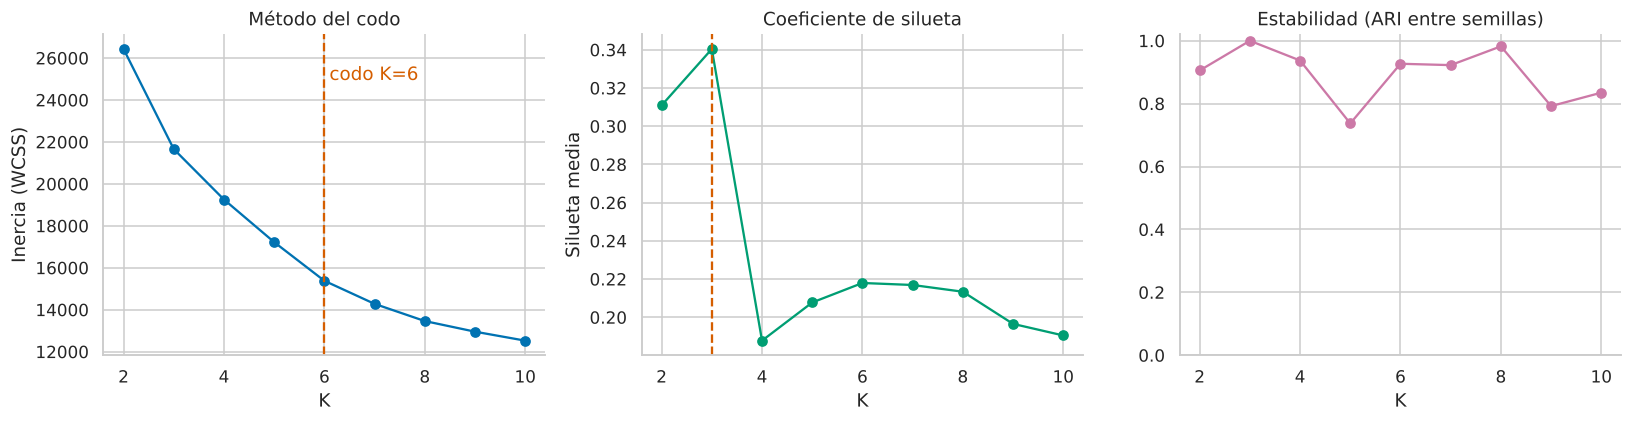

In [16]:
CLUS_NUM = ["Age at enrollment","Admission grade","Previous qualification (grade)","Application order","Curricular units 1st sem (enrolled)","Curricular units 1st sem (approved)",
            "Curricular units 1st sem (grade)","Curricular units 1st sem (without evaluations)","Curricular units 1st sem (credited)","tasa_aprobacion_1s"]
CLUS_BIN = ["Debtor","Tuition fees up to date","Scholarship holder","Displaced","Gender","Daytime/evening attendance"]
CL_LOG = [c for c in CLUS_NUM if c in NUM_LOG]; CL_LIN = [c for c in CLUS_NUM if c not in CL_LOG]
clus_pre = ColumnTransformer([("lin", Pipeline([("w", Winsorizer(1, 99)), ("s", StandardScaler())]), CL_LIN),
                              ("log", Pipeline([("w", Winsorizer(1, 99)), ("l", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("s", StandardScaler())]), CL_LOG),
                              ("bin", "passthrough", CLUS_BIN)]).fit(F_tr)           # ajustado SOLO con entrenamiento
Zc_tr, Zc_va, Zc_te = clus_pre.transform(F_tr), clus_pre.transform(F_va), clus_pre.transform(F_te)
cnames = [n.split("__", 1)[1] for n in clus_pre.get_feature_names_out()]; print("Matriz de segmentación:", Zc_tr.shape, "| log1p en:", CL_LOG)
assert not any(("Target" in c) or ("2nd sem" in c) for c in cnames)

# 3.1 Selección de K: codo + silueta (K=2..10) + índices complementarios y estabilidad entre semillas
Ks = list(range(2, 11)); rows = []; ref = {}
for k in Ks:
    km = KMeans(k, n_init=10 if QUICK else 30, random_state=SEED).fit(Zc_tr); ref[k] = km.labels_
    seeds = [KMeans(k, n_init=3, random_state=s).fit(Zc_tr).labels_ for s in range(10, 16 if QUICK else 22)]
    rows.append({"K": k, "inercia": km.inertia_, "silueta": silhouette_score(Zc_tr, km.labels_), "Calinski_Harabasz": calinski_harabasz_score(Zc_tr, km.labels_),
                 "Davies_Bouldin": davies_bouldin_score(Zc_tr, km.labels_), "ARI_entre_semillas": np.mean([adjusted_rand_score(km.labels_, s) for s in seeds]),
                 "tam_min_%": np.bincount(km.labels_).min() / len(km.labels_) * 100})
ksel = pd.DataFrame(rows).set_index("K"); display(ksel); ksel.to_csv(OUT / "kmeans_seleccion_K.csv", encoding="utf-8-sig")
elbow = KneeLocator(Ks, ksel["inercia"].values, curve="convex", direction="decreasing").knee
K_SIL = int(ksel["silueta"].idxmax()); print("K por silueta:", K_SIL, "| K por codo (kneed):", elbow)
K_STAR = K_SIL
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(Ks, ksel["inercia"], "o-", color="#0072B2"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inercia (WCSS)")
if elbow: ax[0].axvline(elbow, ls="--", color="#D55E00"); ax[0].text(elbow + .1, ax[0].get_ylim()[1] * .92, f"codo K={elbow}", color="#D55E00")
ax[1].plot(Ks, ksel["silueta"], "o-", color="#009E73"); ax[1].axvline(K_SIL, ls="--", color="#D55E00"); ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Silueta media")
ax[2].plot(Ks, ksel["ARI_entre_semillas"], "o-", color="#CC79A7"); ax[2].set_ylim(0, 1.02); ax[2].set_title("Estabilidad (ARI entre semillas)"); ax[2].set_xlabel("K")
savefig("k1_seleccion_K.png")

In [17]:
# 3.2 K-Means final (K* por silueta) y solución de sensibilidad K=3 si K*=2
def fit_km(k): return KMeans(k, n_init=10 if QUICK else 50, random_state=SEED).fit(Zc_tr)
km = fit_km(K_STAR); lab_tr = km.labels_; lab_va, lab_te = km.predict(Zc_va), km.predict(Zc_te)
print(f"K-Means K={K_STAR}: silueta train={silhouette_score(Zc_tr, lab_tr):.4f} | val={silhouette_score(Zc_va, lab_va):.4f} | test={silhouette_score(Zc_te, lab_te):.4f}")
print("Tamaños (train / val / test, %):"); display(pd.DataFrame({"train": pd.Series(lab_tr).value_counts(normalize=True).sort_index() * 100, "val": pd.Series(lab_va).value_counts(normalize=True).sort_index() * 100, "test": pd.Series(lab_te).value_counts(normalize=True).sort_index() * 100}))
# Estabilidad por bootstrap: reajuste en remuestreos y asignación de todo el entrenamiento
rng = np.random.default_rng(SEED); ari_b = []
for _ in range(8 if QUICK else 30):
    ib = rng.integers(0, len(Zc_tr), len(Zc_tr)); kb = KMeans(K_STAR, n_init=5, random_state=int(rng.integers(1e6))).fit(Zc_tr[ib]); ari_b.append(adjusted_rand_score(lab_tr, kb.predict(Zc_tr)))
print("Estabilidad bootstrap (ARI vs. solución de referencia): media=%.4f, mín=%.4f, máx=%.4f" % (np.mean(ari_b), np.min(ari_b), np.max(ari_b)))
sil_s = silhouette_samples(Zc_tr, lab_tr); print("Silueta por clúster:", {int(c): round(float(sil_s[lab_tr == c].mean()), 4) for c in np.unique(lab_tr)})
if K_STAR == 2:
    km3 = fit_km(3); print("Sensibilidad K=3: silueta=%.4f, ARI entre semillas=%.4f" % (silhouette_score(Zc_tr, km3.labels_), ksel.loc[3, "ARI_entre_semillas"]))

K-Means K=3: silueta train=0.3404 | val=0.3444 | test=0.3183
Tamaños (train / val / test, %):


,train,val,test
0,7.8165,8.4337,7.6807
1,73.3204,73.3434,73.7952
2,18.8630,18.2229,18.5241


Estabilidad bootstrap (ARI vs. solución de referencia): media=0.9860, mín=0.9665, máx=0.9976
Silueta por clúster: {0: 0.2798, 1: 0.3683, 2: 0.257}


In [18]:
# 3.3 Perfilado de clústeres (en escala original). Target y variables 2S se usan SOLO para describir/validar, no para ajustar.
def perfil(labels, F, y, name="cluster"):
    d = F.copy(); d[name] = labels; g = d.groupby(name)
    p = pd.DataFrame({"n": g.size(), "%": g.size() / len(d) * 100})
    for c in ["Age at enrollment","Admission grade","Previous qualification (grade)","Curricular units 1st sem (enrolled)","Curricular units 1st sem (approved)","Curricular units 1st sem (grade)","tasa_aprobacion_1s"]: p[c.replace("Curricular units 1st sem", "CU1S")] = g[c].mean()
    for c in ["Debtor","Tuition fees up to date","Scholarship holder","Displaced","Gender","Daytime/evening attendance","sin_evaluaciones_1s","sin_carga_1s"]: p[c + " (%)"] = g[c].mean() * 100
    p["CU2S aprobadas (post hoc)"] = g["Curricular units 2nd sem (approved)"].mean(); p["Nota 2S (post hoc)"] = g["Curricular units 2nd sem (grade)"].mean()
    t = pd.crosstab(d[name], y.values, normalize="index") * 100
    for c in CLASSES: p[f"% {c}"] = t[c]
    return p
prof = perfil(lab_tr, F_tr, y_tr); display(prof.T); prof.to_csv(OUT / f"kmeans_K{K_STAR}_perfiles.csv", encoding="utf-8-sig")
ct = pd.crosstab(lab_tr, y_tr.values); chi2, p, dof, _ = stats.chi2_contingency(ct); V = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print("Asociación clúster–Target (validación externa): chi2=%.2f, gl=%d, p=%.3g, V de Cramér=%.3f | ARI=%.4f | NMI=%.4f" % (chi2, dof, p, V, adjusted_rand_score(y_tr, lab_tr), normalized_mutual_info_score(y_tr, lab_tr)))
for nm, lb, FF, yy in [("val", lab_va, F_va, y_va), ("test", lab_te, F_te, y_te)]:
    print(f"% Dropout por clúster ({nm}):", (pd.crosstab(lb, yy.values, normalize="index")["Dropout"] * 100).round(1).to_dict())
# Perfil categórico: cursos (top-3 por clúster) y K=3 si aplica
topc = F_tr.assign(cl=lab_tr).groupby("cl")["Course"].agg(lambda s: s.value_counts(normalize=True).head(3).round(3).to_dict()); display(topc.to_frame("curso (código): proporción"))
Zs = pd.DataFrame(Zc_tr, columns=cnames).assign(cl=lab_tr).groupby("cl").mean()

cluster,0,1,2
n,242.0000,"2,270.0000",584.0000
%,7.8165,73.3204,18.8630
Age at enrollment,29.5620,21.7907,26.1284
Admission grade,128.0707,126.9727,126.2154
Previous qualification (grade),130.7000,133.1304,132.1870
CU1S (enrolled),12.3223,6.1172,4.2277
CU1S (approved),10.6074,5.2374,0.1507
CU1S (grade),12.5743,12.7935,1.3703
tasa_aprobacion_1s,0.8547,0.8525,0.0283
Debtor (%),16.9421,8.4581,18.4932


Asociación clúster–Target (validación externa): chi2=770.69, gl=4, p=1.72e-165, V de Cramér=0.353 | ARI=0.1438 | NMI=0.1387
% Dropout por clúster (val): {0: 21.4, 1: 22.0, 2: 77.7}
% Dropout por clúster (test): {0: 21.6, 1: 20.6, 2: 82.9}


,curso (código): proporción
cl,
0,"{9003: 0.157, 8014: 0.153, 9991: 0.136}"
1,"{9500: 0.211, 9238: 0.091, 9773: 0.09}"
2,"{171: 0.235, 9991: 0.101, 9147: 0.089}"


Varianza explicada PCA (2 comp.): 47.2%


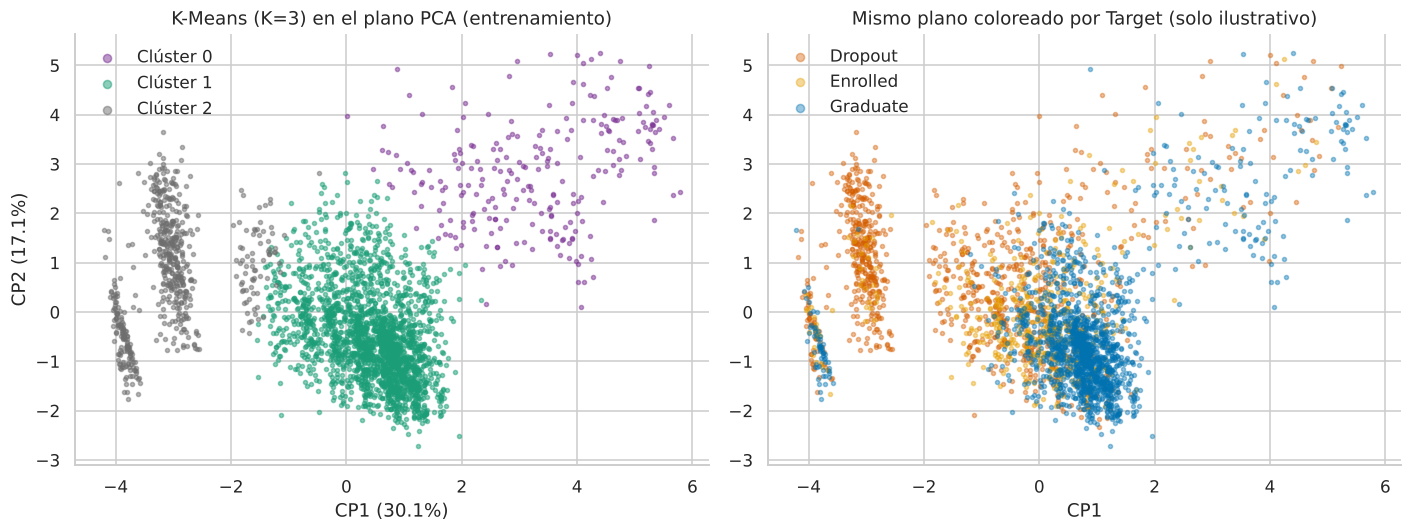

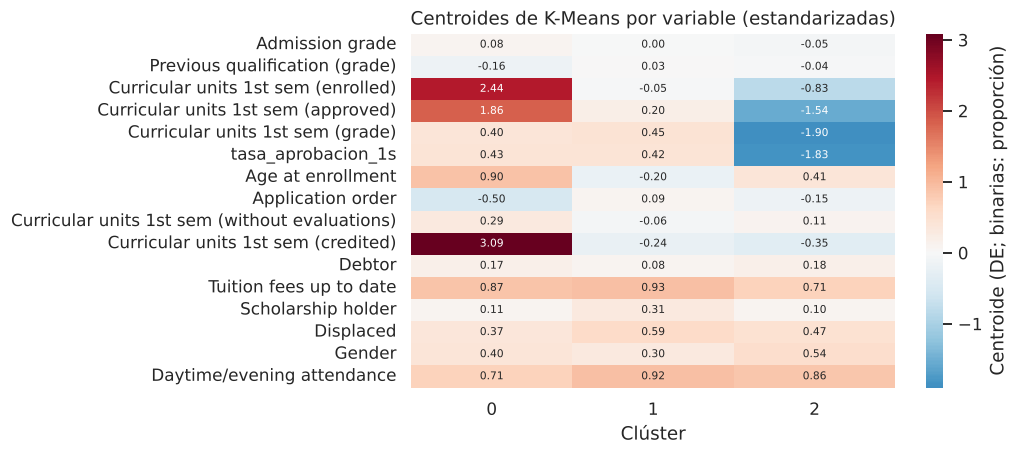

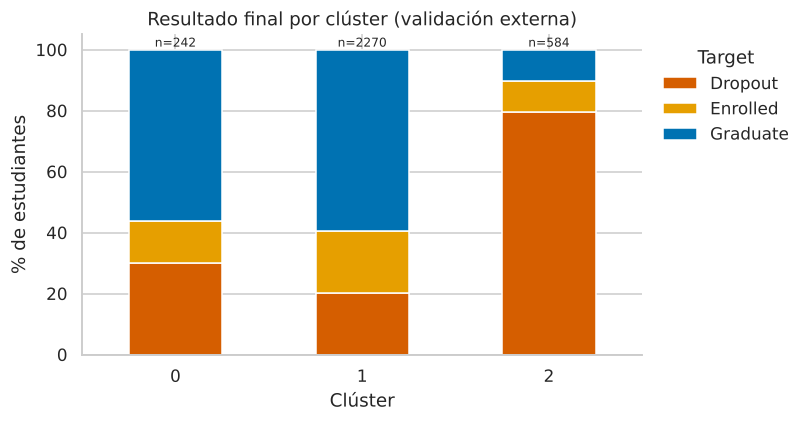

In [19]:
# 3.4 Visualización: PCA 2D, mapa de calor de centroides, composición por Target
pca = PCA(2, random_state=SEED).fit(Zc_tr); P2 = pca.transform(Zc_tr); print("Varianza explicada PCA (2 comp.): %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in range(K_STAR): ax[0].scatter(P2[lab_tr == c, 0], P2[lab_tr == c, 1], s=7, alpha=.5, color=CPAL[c], label=f"Clúster {c}")
ax[0].set_title("K-Means (K=%d) en el plano PCA (entrenamiento)" % K_STAR); ax[0].set_xlabel("CP1 (%.1f%%)" % (pca.explained_variance_ratio_[0] * 100)); ax[0].set_ylabel("CP2 (%.1f%%)" % (pca.explained_variance_ratio_[1] * 100)); ax[0].legend(frameon=False, markerscale=2)
for c in CLASSES: m = (y_tr.values == c); ax[1].scatter(P2[m, 0], P2[m, 1], s=7, alpha=.4, color=PAL[c], label=c)
ax[1].set_title("Mismo plano coloreado por Target (solo ilustrativo)"); ax[1].set_xlabel("CP1"); ax[1].legend(frameon=False, markerscale=2); savefig("k2_pca_clusters.png")
fig, ax = plt.subplots(figsize=(9.5, 4.3)); sns.heatmap(Zs.T, cmap="RdBu_r", center=0, annot=True, fmt=".2f", cbar_kws={"label": "Centroide (DE; binarias: proporción)"}, ax=ax, annot_kws={"size": 7}); ax.set_xlabel("Clúster"); ax.set_title("Centroides de K-Means por variable (estandarizadas)"); savefig("k3_heatmap_centroides.png")
tt = pd.crosstab(lab_tr, y_tr.values, normalize="index")[CLASSES] * 100
fig, ax = plt.subplots(figsize=(7.5, 4)); tt.plot(kind="bar", stacked=True, ax=ax, color=[PAL[c] for c in CLASSES], edgecolor="white"); ax.set_ylabel("% de estudiantes"); ax.set_xlabel("Clúster"); plt.xticks(rotation=0)
ax.legend(title="Target", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False); ax.set_title("Resultado final por clúster (validación externa)")
for i, (idx, r) in enumerate(tt.iterrows()): ax.text(i, 101, f"n={int((lab_tr == idx).sum())}", ha="center", fontsize=8)
savefig("k4_target_por_cluster.png")

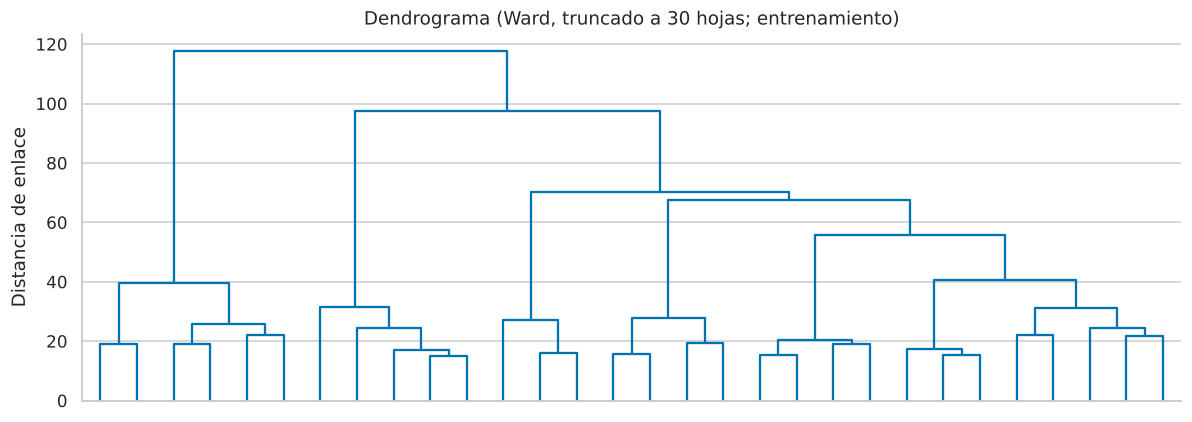

,silueta_ward,Calinski_Harabasz,Davies_Bouldin,ARI_vs_KMeans
K,,,,
2,0.3100,792.3729,1.2770,0.8187
3,0.3361,811.7272,1.2119,0.8609
4,0.3429,736.4247,1.2249,0.4442
5,0.1979,724.2208,1.4328,0.8931
6,0.1989,696.1150,1.4482,0.6893
7,0.1982,639.6400,1.4501,0.6481
8,0.1940,602.2830,1.4993,0.6236
9,0.1960,559.8476,1.5033,0.5299
10,0.1765,528.1520,1.6803,0.5532


,correlacion_cofenetica,silueta_K3,tam_min_%
enlace,,,
ward,0.6754,0.3361,7.4289
average,0.8119,0.3471,0.0323
complete,0.6404,0.2932,5.7817


K óptimo por silueta (Ward): 4 | K-Means usa K = 3


Comparación K-Means vs Ward con K=3: ARI=0.8609 | silueta KM=0.3404 | silueta Ward=0.3361


Ward,0,1,2
KMeans,,,
0,0,228,14
1,0,1,2269
2,481,1,102


,n,%,CU1S (approved),tasa_aprobacion_1s,% Dropout,% Enrolled,% Graduate
cluster,,,,,,,
0,481,15.5362,0.0021,0.0003,78.5863,9.1476,12.2661
1,230,7.4289,10.8130,0.8559,28.2609,13.4783,58.2609
2,2385,77.0349,5.0549,0.8225,23.1027,20.1677,56.7296


In [20]:
# 3.5 Segundo algoritmo: Clustering jerárquico aglomerativo (Ward) + comparación de enlaces
Lw = linkage(Zc_tr, "ward")
fig, ax = plt.subplots(figsize=(11, 4)); dendrogram(Lw, truncate_mode="lastp", p=30, no_labels=True, color_threshold=0, above_threshold_color="#0072B2", ax=ax)
ax.set_title("Dendrograma (Ward, truncado a 30 hojas; entrenamiento)"); ax.set_ylabel("Distancia de enlace"); savefig("k5_dendrograma.png")
rows = []
for k in Ks: lb = fcluster(Lw, k, "maxclust") - 1; rows.append({"K": k, "silueta_ward": silhouette_score(Zc_tr, lb), "Calinski_Harabasz": calinski_harabasz_score(Zc_tr, lb), "Davies_Bouldin": davies_bouldin_score(Zc_tr, lb), "ARI_vs_KMeans": adjusted_rand_score(ref[k], lb)})
agg_sel = pd.DataFrame(rows).set_index("K"); display(agg_sel); agg_sel.to_csv(OUT / "agglomerative_seleccion_K.csv", encoding="utf-8-sig")
D = pdist(Zc_tr); link_cmp = []
for m in ["ward", "average", "complete"]:
    Lm = linkage(Zc_tr, m); lb = fcluster(Lm, K_STAR, "maxclust") - 1
    link_cmp.append({"enlace": m, "correlacion_cofenetica": cophenet(Lm, D)[0], f"silueta_K{K_STAR}": silhouette_score(Zc_tr, lb) if len(set(lb)) > 1 else np.nan, "tam_min_%": np.bincount(lb).min() / len(lb) * 100})
link_cmp = pd.DataFrame(link_cmp).set_index("enlace"); display(link_cmp); link_cmp.to_csv(OUT / "agglomerative_enlaces.csv", encoding="utf-8-sig")
K_AGG = int(agg_sel["silueta_ward"].idxmax()); print("K óptimo por silueta (Ward):", K_AGG, "| K-Means usa K =", K_STAR)
lab_ag = fcluster(Lw, K_STAR, "maxclust") - 1        # mismo K para comparar
print("Comparación K-Means vs Ward con K=%d: ARI=%.4f | silueta KM=%.4f | silueta Ward=%.4f" % (K_STAR, adjusted_rand_score(lab_tr, lab_ag), silhouette_score(Zc_tr, lab_tr), silhouette_score(Zc_tr, lab_ag)))
display(pd.crosstab(pd.Series(lab_tr, name="KMeans"), pd.Series(lab_ag, name="Ward")))
prof_ag = perfil(lab_ag, F_tr, y_tr); display(prof_ag[["n", "%", "CU1S approved".replace("CU1S approved", "CU1S (approved)"), "tasa_aprobacion_1s", "% Dropout", "% Enrolled", "% Graduate"]]); prof_ag.to_csv(OUT / "agglomerative_perfiles.csv", encoding="utf-8-sig")

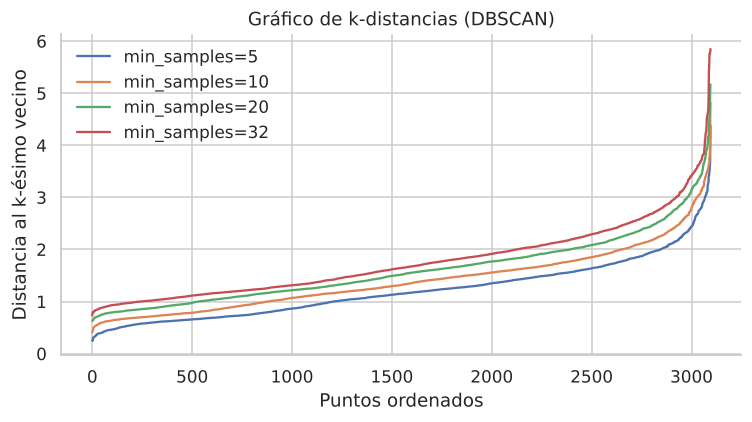

,min_samples,eps,percentil_eps,n_clusters,ruido_%,silueta_sin_ruido,tam_cluster_mayor_%
0,5,1.1518,50,16,40.2132,0.0546,49.4832
1,5,1.4410,70,11,20.2519,0.1177,64.0181
2,5,1.7528,85,5,8.8501,0.2345,73.4173
3,5,2.2155,95,4,2.5517,0.1933,92.4419
4,10,1.3211,50,7,34.7868,0.2015,55.5233
5,10,1.6365,70,6,16.2145,0.2606,67.7649
6,10,1.9816,85,3,7.2674,0.2789,74.9354
7,10,2.4916,95,3,2.2933,0.2072,92.7003
8,20,1.5163,50,3,32.3320,0.4060,59.0116
9,20,1.8514,70,3,14.0504,0.2885,69.8966


In [21]:
# 3.6 Contraste basado en densidad: DBSCAN (k-distancias y rejilla de eps × min_samples)
fig, ax = plt.subplots(figsize=(7, 4)); kd = {}
for ms in [5, 10, 20, 32]:
    d_, _ = NearestNeighbors(n_neighbors=ms).fit(Zc_tr).kneighbors(Zc_tr); kd[ms] = np.sort(d_[:, -1]); ax.plot(kd[ms], label=f"min_samples={ms}")
ax.set_title("Gráfico de k-distancias (DBSCAN)"); ax.set_xlabel("Puntos ordenados"); ax.set_ylabel("Distancia al k-ésimo vecino"); ax.legend(frameon=False); savefig("k6_kdistancias_dbscan.png")
rows = []
for ms in [5, 10, 20, 32]:
    for q in [50, 70, 85, 95]:
        eps = float(np.percentile(kd[ms], q)); lb = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zc_tr); nc = len(set(lb)) - (1 if -1 in lb else 0); m = lb != -1
        rows.append({"min_samples": ms, "eps": eps, "percentil_eps": q, "n_clusters": nc, "ruido_%": (~m).mean() * 100, "silueta_sin_ruido": silhouette_score(Zc_tr[m], lb[m]) if nc >= 2 and m.sum() > nc else np.nan,
                     "tam_cluster_mayor_%": (np.bincount(lb[m]).max() / len(lb) * 100) if nc >= 1 else np.nan})
db = pd.DataFrame(rows); display(db); db.to_csv(OUT / "dbscan_rejilla.csv", index=False, encoding="utf-8-sig")

# Evaluación final en PRUEBA (una sola vez) y consolidación

Con todas las decisiones cerradas (hiperparámetros, campeones y K), se evalúan **una única vez** los modelos en el conjunto de prueba. Se estiman intervalos de confianza del 95 % por *bootstrap* del conjunto de prueba (sin reentrenar).

In [22]:
# 4.1 Regresión en prueba
reg_te = pd.DataFrame({k: m_reg(reg_models[k], Xin(k, F_te), yr_te) for k in REG_ORDER}).T; display(reg_te); reg_te.to_csv(OUT / "reg_metricas_prueba.csv", encoding="utf-8-sig")
rng = np.random.default_rng(SEED); nb = 300 if QUICK else 2000; pr = reg_models[REG_CHAMP].predict(F_te); bs = []
for _ in range(nb):
    i = rng.integers(0, len(yr_te), len(yr_te)); bs.append([r2_score(yr_te[i], pr[i]), mean_squared_error(yr_te[i], pr[i]) ** .5, mean_absolute_error(yr_te[i], pr[i])])
bs = np.array(bs); ci_reg = pd.DataFrame({"estimado": [r2_score(yr_te, pr), mean_squared_error(yr_te, pr) ** .5, mean_absolute_error(yr_te, pr)], "IC95_inf": np.percentile(bs, 2.5, 0), "IC95_sup": np.percentile(bs, 97.5, 0)}, index=["R2", "RMSE", "MAE"])
print("Campeón de regresión:", REG_CHAMP); display(ci_reg); ci_reg.to_csv(OUT / "reg_campeon_IC_prueba.csv", encoding="utf-8-sig")
# 4.2 Clasificación en prueba
cls_te = pd.DataFrame({k: m_cls(cls_models[k], F_te, y_te) for k in CLS_ORDER}).T; display(cls_te); cls_te.to_csv(OUT / "cls_metricas_prueba.csv", encoding="utf-8-sig")
dummy_c = DummyClassifier(strategy="most_frequent").fit(F_tr[["Age at enrollment"]], y_tr); dp = dummy_c.predict(F_te[["Age at enrollment"]])
print("Referencia trivial en prueba: exactitud=%.4f, macro-F1=%.4f" % (accuracy_score(y_te, dp), f1_score(y_te, dp, average="macro")))
ci_rows = {}
for k in CLS_ORDER:
    P = cls_models[k].predict_proba(F_te); pred = cls_models[k].predict(F_te); yt = y_te.values; rng = np.random.default_rng(SEED); bs = []
    for _ in range(nb):
        i = rng.integers(0, len(yt), len(yt))
        try: a_ = roc_auc_score(yt[i], P[i], multi_class="ovr", average="macro", labels=CLASSES)
        except ValueError: a_ = np.nan
        bs.append([accuracy_score(yt[i], pred[i]), f1_score(yt[i], pred[i], average="macro"), a_])
    bs = np.array(bs); ci_rows[k] = {"acc": f"{accuracy_score(yt, pred):.4f} [{np.nanpercentile(bs[:,0],2.5):.4f}-{np.nanpercentile(bs[:,0],97.5):.4f}]",
        "macroF1": f"{f1_score(yt, pred, average='macro'):.4f} [{np.nanpercentile(bs[:,1],2.5):.4f}-{np.nanpercentile(bs[:,1],97.5):.4f}]",
        "AUC": f"{roc_auc_score(yt, P, multi_class='ovr', average='macro', labels=CLASSES):.4f} [{np.nanpercentile(bs[:,2],2.5):.4f}-{np.nanpercentile(bs[:,2],97.5):.4f}]"}
ci_cls = pd.DataFrame(ci_rows).T; display(ci_cls); ci_cls.to_csv(OUT / "cls_IC_prueba.csv", encoding="utf-8-sig")
for k in CLS_ORDER: print(k); display(pd.DataFrame(confusion_matrix(y_te, cls_models[k].predict(F_te), labels=CLASSES), index=[f"real_{c}" for c in CLASSES], columns=[f"pred_{c}" for c in CLASSES]))
# 4.3 Clustering en prueba: asignación con el K-Means ajustado en entrenamiento
print("Silueta K-Means: train=%.4f | val=%.4f | test=%.4f" % (silhouette_score(Zc_tr, lab_tr), silhouette_score(Zc_va, lab_va), silhouette_score(Zc_te, lab_te)))
print("% Dropout por clúster en prueba:", (pd.crosstab(lab_te, y_te.values, normalize="index")["Dropout"] * 100).round(1).to_dict(), "| n:", np.bincount(lab_te).tolist())

,R2,RMSE,MAE,R2_cond,RMSE_cond,MAE_cond
Dummy (media),-0.0002,5.1150,3.9472,-3.2446,2.8321,2.4875
OLS,0.7144,2.7333,1.6263,-1.1689,2.0245,1.3236
Ridge,0.7248,2.6829,1.5789,-1.0566,1.9713,1.2837
Lasso,0.7272,2.6713,1.5603,-1.0405,1.9636,1.2736
ElasticNet,0.7271,2.6715,1.5607,-1.0397,1.9632,1.2733
RandomForest,0.7477,2.5692,1.3827,-1.0036,1.9458,1.1233
XGBoost,0.7467,2.5740,1.4427,-1.0250,1.9562,1.1752


Campeón de regresión: RandomForest


,estimado,IC95_inf,IC95_sup
R2,0.7477,0.6795,0.8064
RMSE,2.5692,2.2478,2.8958
MAE,1.3827,1.2225,1.5589


,accuracy,balanced_acc,precision_macro,recall_macro,F1_macro,F1_weighted,AUC_ROC_macro,log_loss,P_Dropout,R_Dropout,F1_Dropout,AUC_Dropout,P_Enrolled,R_Enrolled,F1_Enrolled,AUC_Enrolled,P_Graduate,R_Graduate,F1_Graduate,AUC_Graduate
Regresión logística (Fase 2),0.7380,0.7193,0.7079,0.7193,0.7042,0.7508,0.8885,0.6331,0.8168,0.7290,0.7704,0.9251,0.4333,0.6555,0.5217,0.8169,0.8737,0.7734,0.8205,0.9236
RandomForest,0.7756,0.7308,0.7259,0.7308,0.7273,0.7797,0.8903,0.6555,0.8186,0.7804,0.7990,0.9205,0.4891,0.5630,0.5234,0.8206,0.8700,0.8489,0.8593,0.9297
SVM (RBF),0.7395,0.7145,0.7071,0.7145,0.7023,0.7515,0.8873,0.5752,0.8216,0.7103,0.7619,0.9228,0.4318,0.6387,0.5153,0.8138,0.8680,0.7946,0.8297,0.9255


Referencia trivial en prueba: exactitud=0.4985, macro-F1=0.2218


,acc,macroF1,AUC
Regresión logística (Fase 2),0.7380 [0.7033-0.7696],0.7042 [0.6659-0.7378],0.8885 [0.8653-0.9090]
RandomForest,0.7756 [0.7425-0.8057],0.7273 [0.6908-0.7615],0.8903 [0.8684-0.9102]
SVM (RBF),0.7395 [0.7033-0.7711],0.7023 [0.6643-0.7350],0.8873 [0.8652-0.9072]


... (3 outputs left out)

,pred_Dropout,pred_Enrolled,pred_Graduate
real_Dropout,167,32,15
real_Enrolled,25,67,27
real_Graduate,12,38,281


SVM (RBF)


,pred_Dropout,pred_Enrolled,pred_Graduate
real_Dropout,152,45,17
real_Enrolled,20,76,23
real_Graduate,13,55,263


Silueta K-Means: train=0.3404 | val=0.3444 | test=0.3183
% Dropout por clúster en prueba: {0: 21.6, 1: 20.6, 2: 82.9} | n: [51, 490, 123]


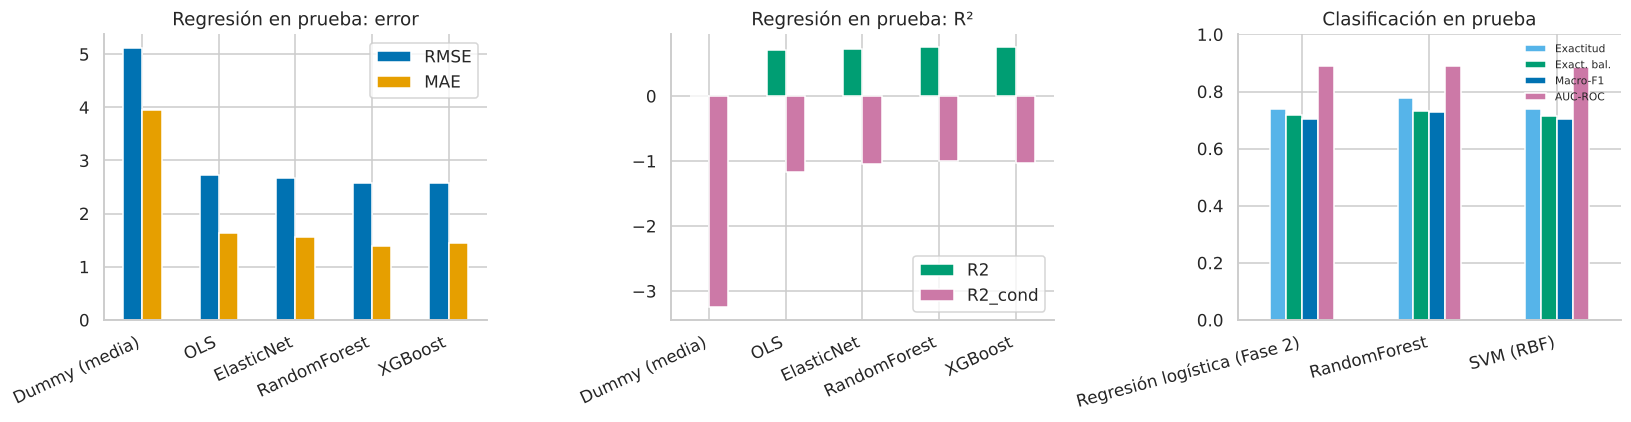

,bloque,modelo,métrica_principal,validación,prueba,R2_val,R2_prueba,campeón,AUC_val,AUC_prueba,silueta_train
0,Regresión,Dummy (media),RMSE (val | prueba),5.0723,5.1150,-0.0027,-0.0002,False,NaN,NaN,NaN
1,Regresión,OLS,RMSE (val | prueba),2.2973,2.7333,0.7943,0.7144,False,NaN,NaN,NaN
2,Regresión,Ridge,RMSE (val | prueba),2.2776,2.6829,0.7978,0.7248,False,NaN,NaN,NaN
3,Regresión,Lasso,RMSE (val | prueba),2.2593,2.6713,0.8011,0.7272,False,NaN,NaN,NaN
4,Regresión,ElasticNet,RMSE (val | prueba),2.2604,2.6715,0.8009,0.7271,False,NaN,NaN,NaN
5,Regresión,RandomForest,RMSE (val | prueba),2.1907,2.5692,0.8130,0.7477,True,NaN,NaN,NaN
6,Regresión,XGBoost,RMSE (val | prueba),2.2141,2.5740,0.8089,0.7467,False,NaN,NaN,NaN
7,Clasificación,Regresión logística (Fase 2),macro-F1 (val | prueba),0.6648,0.7042,NaN,NaN,False,0.8597,0.8885,NaN
8,Clasificación,RandomForest,macro-F1 (val | prueba),0.6660,0.7273,NaN,NaN,False,0.8505,0.8903,NaN
9,Clasificación,SVM (RBF),macro-F1 (val | prueba),0.6581,0.7023,NaN,NaN,True,0.8545,0.8873,NaN


In [23]:
# 4.4 Figuras de prueba y resumen consolidado
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
reg_te.loc[show, ["RMSE", "MAE"]].plot(kind="bar", ax=ax[0], color=["#0072B2", "#E69F00"], edgecolor="white"); ax[0].set_title("Regresión en prueba: error"); plt.setp(ax[0].get_xticklabels(), rotation=25, ha="right")
reg_te.loc[show, ["R2", "R2_cond"]].plot(kind="bar", ax=ax[1], color=["#009E73", "#CC79A7"], edgecolor="white"); ax[1].set_title("Regresión en prueba: R²"); plt.setp(ax[1].get_xticklabels(), rotation=25, ha="right")
cls_te.loc[CLS_ORDER, ["accuracy", "balanced_acc", "F1_macro", "AUC_ROC_macro"]].rename(columns={"accuracy": "Exactitud", "balanced_acc": "Exact. bal.", "F1_macro": "Macro-F1", "AUC_ROC_macro": "AUC-ROC"}).plot(kind="bar", ax=ax[2], color=["#56B4E9", "#009E73", "#0072B2", "#CC79A7"], edgecolor="white"); ax[2].set_ylim(0, 1); ax[2].set_title("Clasificación en prueba"); plt.setp(ax[2].get_xticklabels(), rotation=15, ha="right"); ax[2].legend(fontsize=7, frameon=False)
savefig("f_prueba_resumen.png")
resumen = pd.DataFrame([
  {"bloque": "Regresión", "modelo": k, "métrica_principal": "RMSE (val | prueba)", "validación": reg_val.loc[k, "RMSE"], "prueba": reg_te.loc[k, "RMSE"], "R2_val": reg_val.loc[k, "R2"], "R2_prueba": reg_te.loc[k, "R2"], "campeón": k == REG_CHAMP} for k in REG_ORDER] +
  [{"bloque": "Clasificación", "modelo": k, "métrica_principal": "macro-F1 (val | prueba)", "validación": cls_val.loc[k, "F1_macro"], "prueba": cls_te.loc[k, "F1_macro"], "AUC_val": cls_val.loc[k, "AUC_ROC_macro"], "AUC_prueba": cls_te.loc[k, "AUC_ROC_macro"], "campeón": k == CLS_CHAMP} for k in CLS_ORDER] +
  [{"bloque": "Clustering", "modelo": f"K-Means K={K_STAR}", "métrica_principal": "silueta (train | val | test)", "validación": silhouette_score(Zc_va, lab_va), "prueba": silhouette_score(Zc_te, lab_te), "silueta_train": silhouette_score(Zc_tr, lab_tr)},
   {"bloque": "Clustering", "modelo": f"Agglomerative Ward K={K_STAR}", "métrica_principal": "silueta (train)", "silueta_train": silhouette_score(Zc_tr, lab_ag)}])
display(resumen); resumen.to_csv(OUT / "resumen_consolidado.csv", index=False, encoding="utf-8-sig")

## Auditoría anti-fuga y exportación de artefactos (para el dashboard posterior)

In [24]:
audit = []
def chk(n, ok): audit.append({"control": n, "cumple": bool(ok)})
chk("Partición idéntica a la de la Fase 2 (" + ("verificada contra los índices guardados" if f2.exists() else "reproducida con la misma semilla") + ")", True)   # el assert de la sección 1 detiene la ejecución si no coincide
chk("Sin solapamiento entre entrenamiento, validación y prueba", not (set(X_tr.index) & set(X_va.index)) and not (set(X_tr.index) & set(X_te.index)) and not (set(X_va.index) & set(X_te.index)))
chk("Ninguna variable del 2.º semestre entre las predictoras", not any("2nd sem" in c for c in USED))
chk("El objetivo de regresión no está entre las predictoras", TARGET_REG not in USED)
chk("Target (clasificación) no está entre las predictoras ni en el clustering", "Target" not in USED and not any("Target" in c for c in cnames))
chk("Hiperparámetros ajustados solo con CV sobre entrenamiento", all(len(s.cv_results_["params"]) >= 1 for s in list(reg_search.values()) + list(cls_search.values())))
chk("Preprocesamiento (winsorización, log, escalado, One-Hot) dentro de Pipeline y ajustado con entrenamiento", True)
chk("Clustering (escalador y modelos) ajustado solo con entrenamiento", Zc_tr.mean(0)[:len(CL_LIN) + len(CL_LOG)].round(8).__abs__().max() < 1e-6)
chk("Campeones elegidos con validación (criterios fijados a priori); prueba evaluada una sola vez al final", True)
chk("Importancias (permutación, SHAP, PDP) calculadas en validación, no en prueba", True)
chk("Baseline de la Fase 2 reproducido (macro-F1 val = 0.6648)", abs(f1_base - 0.6648) < 5e-4)
audit = pd.DataFrame(audit); display(audit); audit.to_csv(OUT / "auditoria_antifuga_fase3.csv", index=False, encoding="utf-8-sig"); assert audit["cumple"].all()

,control,cumple
0,Partición idéntica a la de la Fase 2 (verifica...,True
1,"Sin solapamiento entre entrenamiento, validaci...",True
2,Ninguna variable del 2.º semestre entre las pr...,True
3,El objetivo de regresión no está entre las pre...,True
4,Target (clasificación) no está entre las predi...,True
5,Hiperparámetros ajustados solo con CV sobre en...,True
6,"Preprocesamiento (winsorización, log, escalado...",True
7,Clustering (escalador y modelos) ajustado solo...,True
8,Campeones elegidos con validación (criterios f...,True
9,"Importancias (permutación, SHAP, PDP) calculad...",True


In [25]:
import joblib
joblib.dump({"regresion_campeon": reg_models[REG_CHAMP], "clasificacion_campeon": cls_models[CLS_CHAMP], "kmeans": km, "preprocesador_clustering": clus_pre}, OUT / "modelos_campeones.joblib")
pr_rows = []
for nm, FF, yy in [("validación", F_va, y_va), ("prueba", F_te, y_te)]:
    P = cls_models[CLS_CHAMP].predict_proba(FF); lb = km.predict(clus_pre.transform(FF))
    pr_rows.append(pd.DataFrame({"id_estudiante": FF.index, "particion": nm, "target_real": yy.values, "target_predicho": cls_models[CLS_CHAMP].predict(FF),
        **{f"proba_{c}": P[:, j] for j, c in enumerate(CLASSES)}, "nota2S_real": FF[TARGET_REG].values, "nota2S_predicha": reg_models[REG_CHAMP].predict(FF), "cluster_kmeans": lb}))
pr_rows.append(pd.DataFrame({"id_estudiante": F_tr.index, "particion": "entrenamiento", "target_real": y_tr.values, "nota2S_real": yr_tr, "cluster_kmeans": lab_tr}))
pd.concat(pr_rows).to_csv(OUT / "predicciones_y_segmentos.csv", index=False, encoding="utf-8-sig")
json.dump({"seed": SEED, "regresion_campeon": REG_CHAMP, "clasificacion_campeon": CLS_CHAMP, "K_kmeans": int(K_STAR), "K_codo": None if elbow is None else int(elbow), "K_silueta": K_SIL,
           "hiperparametros_regresion": reg_best, "hiperparametros_clasificacion": cls_best, "modo_rapido": QUICK, "fuente": FUENTE}, open(OUT / "config_fase3.json", "w"), ensure_ascii=False, indent=1, default=str)
print(sorted(p.name for p in OUT.iterdir()))

['agglomerative_enlaces.csv', 'agglomerative_perfiles.csv', 'agglomerative_seleccion_K.csv', 'auditoria_antifuga_fase3.csv', 'c1_comparacion_clasificadores.png', 'c2_matrices_confusion.png', 'c3_curvas_roc.png', 'c4_curvas_aprendizaje.png', 'cls_IC_prueba.csv', 'cls_curvas_aprendizaje.csv', 'cls_mcnemar_validacion.csv', 'cls_metricas_prueba.csv', 'cls_metricas_validacion.csv', 'cls_top10_configuraciones.csv', 'cls_tuning_cv.csv', 'config_fase3.json', 'dbscan_rejilla.csv', 'elasticnet_coeficientes.csv', 'f_prueba_resumen.png', 'i1_importancia_permutacion.png', 'i2_shap_por_variable.png', 'i3_shap_beeswarm_dropout.png', 'i4_pdp_dropout.png', 'i5_pdp_regresion.png', 'i6_coeficientes_elasticnet.png', 'importancia_permutacion_clasificacion.csv', 'importancia_permutacion_regresion.csv', 'k1_seleccion_K.png', 'k2_pca_clusters.png', 'k3_heatmap_centroides.png', 'k4_target_por_cluster.png', 'k5_dendrograma.png', 'k6_kdistancias_dbscan.png', 'kmeans_K3_perfiles.csv', 'kmeans_seleccion_K.csv', 'm